# ☕ Klasifikasi Tingkat Kematangan Coffee Cherry
### Proyek Deep Learning: CNN dari Nol vs Transfer Learning MobileNetV2

**Dataset:** [Haris Yunanda — Dataset Coffee Cherry (Kaggle)](https://www.kaggle.com/datasets/harisyunanda/dataset-coffee-cherry)  
**Pendekatan:** *Object detection annotations* → **cropping objek** → **image classification**  
**Fitur unik:** **Grad-CAM** dan **confidence threshold + abstention**  
**Lingkungan:** Google Colab (GPU jika tersedia) · Python · TensorFlow/Keras · Gradio


**Batasan tugas:** Aplikasi menerima *citra satu buah kopi (crop)*, **tidak** mendeteksi semua buah dalam satu foto. YOLO tidak digunakan; yang dipelajari sesuai mata kuliah adalah CNN dan transfer learning.

## Peta isi sesuai instruksi dosen

| Permintaan | Isi notebook |
|---|---|
| **2. Dataset** (a–d) | Unduh, audit format, statistik, sumber dan kompleksitas |
| **3. EDA** (a–f) | Distribusi label, contoh tiap kelas, ukuran citra & objek, temuan; word count/korelasi tabular **tidak berlaku** |
| **4. Preprocessing** (a–e) | Validasi dan duplikasi, crop berdasarkan anotasi, padding, resize, augmentasi, grup split anti-leakage |
| **5. Model** (a–e) | CNN custom, MobileNetV2, diagram/model.summary, konfigurasi, alasan pemilihan; **2 fitur unik** |
| **6. Evaluasi** (a–e) | Accuracy, macro precision/recall/F1, confusion matrix, kurva training, perbandingan dan analisis |
| **7. Teknologi** (a–d) | Python & versi library/GPU, Colab, aplikasi Gradio, paket hosting |

**Alur:** Setup → Metadata sumber → Pembacaan anotasi → EDA → Cleaning/Crop → Split → Preprocessing → CNN → MobileNetV2 → Evaluasi → Grad-CAM → Threshold → Gradio → Ekspor.

**Kompatibilitas anotasi:** pembaca mencoba **YOLO TXT**, **COCO JSON**, atau **Pascal VOC XML** (bergantung berkas yang ada). Nama/urutan kelas YOLO hanya diambil dari file metadata dataset (`data.yaml`, `classes.txt`, dan sejenisnya) atau override eksplisit — **tidak pernah menebak ID kelas**.

---
# 1. Setup lingkungan, konfigurasi, dan informasi perangkat

**Simpan bukti:** hasil versi Python, TensorFlow, scikit-learn, GPU/CPU dan konfigurasi seed. Setelah notebook selesai, grafik/model/CSV akan disimpan dalam direktori proyek.

In [1]:
%pip -q install kagglehub pyyaml gradio opencv-python-headless

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, math, re, shutil, hashlib, platform, time, zipfile, random
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageFile, ImageOps, ImageDraw
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import sklearn
import cv2
import yaml
import kagglehub
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_CNN = 5
EPOCHS_MOBILENET = 5
CROP_MARGIN = 0.10
CLASS_NAMES_OVERRIDE = None  # Jika tak ada metadata YOLO: ISI MANUAL, mis. {0: '...',1:'...',2:'...'} sesuai sumber yang diverifikasi.
DATASET_URL = 'https://www.kaggle.com/datasets/harisyunanda/dataset-coffee-cherry'
ROOT = Path('/content/coffee_cherry_dl') if Path('/content').exists() else Path.cwd() / 'coffee_cherry_dl'
DATA_DIR = ROOT / 'data'
OUTPUT = ROOT / 'hasil'
MODEL_DIR = OUTPUT / 'models'
for d in [ROOT, DATA_DIR, OUTPUT, MODEL_DIR]: d.mkdir(parents=True, exist_ok=True)

versions = {
    'Python': sys.version.split()[0], 'TensorFlow': tf.__version__,
    'NumPy': np.__version__, 'Pandas': pd.__version__,
    'scikit-learn': sklearn.__version__, 'OpenCV': cv2.__version__,
    'Pillow': Image.__version__, 'PyYAML': yaml.__version__,
    'OS': platform.platform(), 'GPU': [x.name for x in tf.config.list_physical_devices('GPU')],
    'Seed': SEED, 'batch_size': BATCH_SIZE, 'img_size': list(IMG_SIZE)
}
print(json.dumps(versions, indent=2, ensure_ascii=False))
(OUTPUT / 'teknologi_versions.json').write_text(json.dumps(versions, indent=2, ensure_ascii=False))

{
  "Python": "3.12.10",
  "TensorFlow": "2.21.0",
  "NumPy": "2.5.4",
  "Pandas": "3.1.0",
  "scikit-learn": "1.9.1",
  "OpenCV": "5.0.0",
  "Pillow": "12.3.0",
  "PyYAML": "6.0.3",
  "OS": "Windows-11-10.0.26200-SP0",
  "GPU": [],
  "Seed": 42,
  "batch_size": 32,
  "img_size": [
    224,
    224
  ]
}


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


305

---
# 2. Dataset yang digunakan (ketentuan 2a–2d)

- **2a — Sumber:** Kaggle, pemilik `harisyunanda`, tautan tercantum di atas.
- **2b — Jumlah, label, format, ukuran:** dihitung di bawah, termasuk jumlah **gambar asli** dan jumlah **bounding box**, yang merupakan dua hal berbeda.
- **2c — Real-world/sintetis:** dataset dideskripsikan sebagai citra buah kopi di lingkungan perkebunan alami; verifikasi visual sampel pada EDA dan cantumkan batasan asal-usul pada laporan.
- **2d — Kompleksitas:** perubahan warna bertahap, objek kecil, occlusion, latar daun, dan kondisi cahaya. Klaim yang relevan dari pengamatan aktual harus dijelaskan di laporan.

**Catatan penting:** Ada perbedaan angka jumlah citra yang dilaporkan dalam publikasi berbeda, jadi **jangan salin angka publikasi**; gunakan angka yang tercetak dari *download* ini. Untuk referensi konteks (bukan sumber jumlah data eksekusi), lihat [penelitian 2026 yang menggunakan dataset Kaggle ini](https://doi.org/10.3389/fpls.2026.1745060).

In [3]:
# Unduh Kaggle. Jika KaggleHub gagal, isi MANUAL_DATASET_DIR dengan path dataset yang
# sudah diunduh dan diekstrak di Colab/Drive. Contoh: '/content/dataset-coffee-cherry'
MANUAL_DATASET_DIR = None
try:
    if MANUAL_DATASET_DIR:
        dataset_root = Path(MANUAL_DATASET_DIR)
    else:
        dataset_root = Path(kagglehub.dataset_download('harisyunanda/dataset-coffee-cherry'))
except Exception as err:
    raise RuntimeError('Unduhan Kaggle gagal. Unduh manual di Kaggle, upload/extract di Colab, '
                       'lalu isi MANUAL_DATASET_DIR pada sel ini. Detail: ' + str(err)) from err
assert dataset_root.exists(), f'Dataset tidak ditemukan: {dataset_root}'
print('Lokasi dataset:', dataset_root)
print('Contoh struktur (maks. 55 file/folder):')
for p in list(sorted(dataset_root.rglob('*')))[:55]:
    print(' -', p.relative_to(dataset_root))

Lokasi dataset: C:\Users\ASUS\.cache\kagglehub\datasets\harisyunanda\dataset-coffee-cherry\versions\1
Contoh struktur (maks. 55 file/folder):
 - classes.txt
 - images
 - images\017df65b-IMG_20241224_094633.jpg
 - images\01a17c48-IMG_20241224_093501.jpg
 - images\020339c2-IMG_20241224_103355.jpg
 - images\02263ffb-IMG_20241224_094305.jpg
 - images\022e25f5-IMG_20241224_093535.jpg
 - images\02faa803-IMG_20241224_094544.jpg
 - images\0334f0bb-IMG_20241224_102351.jpg
 - images\033a17ac-IMG_20241224_093335.jpg
 - images\036e4dd2-IMG_20241224_101441.jpg
 - images\0465314e-IMG_20241224_093138.jpg
 - images\04728d18-IMG_20241224_095933.jpg
 - images\070d0661-IMG_20241224_092940.jpg
 - images\070d2e16-IMG_20241224_101803.jpg
 - images\0807c3af-IMG_20241224_103208.jpg
 - images\08793a95-IMG_20241224_092657.jpg
 - images\08a33d43-IMG_20241224_102158.jpg
 - images\0a0d0b8a-IMG_20241224_103429.jpg
 - images\0a49d4bb-IMG_20241224_103237.jpg
 - images\0a7071cc-IMG_20241224_095530.jpg
 - images\0ba470

In [4]:
# Jika Kaggle mendistribusikan ZIP, ekstrak secara aman di folder kerja (bukan mengubah file sumber).
EXTRACT_DIR = DATA_DIR / 'extracted_archives'
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
archives = [p for p in dataset_root.rglob('*.zip') if p.is_file()]
print('Arsip ZIP ditemukan:', len(archives))
for ix, z in enumerate(archives):
    dest = EXTRACT_DIR / f'{ix:02d}_{z.stem}'
    marker = dest / '.done'
    if marker.exists():
        continue
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(z) as archive:
        for item in archive.infolist():
            target = (dest / item.filename).resolve()
            if not target.is_relative_to(dest.resolve()):
                raise ValueError(f'Path ZIP mencurigakan: {item.filename}')
        archive.extractall(dest)
    marker.touch()
SOURCE_ROOTS = [dataset_root] + ([EXTRACT_DIR] if archives else [])
IMAGE_EXT = {'.jpg','.jpeg','.png','.bmp','.webp'}
all_images = sorted({p.resolve() for root in SOURCE_ROOTS for p in root.rglob('*')
                     if p.is_file() and p.suffix.lower() in IMAGE_EXT})
print('Jumlah file citra ditemukan (sebelum cleaning):', len(all_images))
assert all_images, 'Tidak ada file gambar. Periksa unduhan/format ZIP.'

Arsip ZIP ditemukan: 0
Jumlah file citra ditemukan (sebelum cleaning): 432


## 2.1 Deteksi format anotasi dan kelas

- **YOLO:** `.txt` dengan setiap baris `id x_center y_center width height` ternormalisasi. Metadata kelas umumnya `data.yaml`, `classes.txt`, atau `obj.names`.
- **COCO:** file `.json` yang mempunyai kunci `images`, `annotations`, dan `categories`.
- **Pascal VOC:** file `.xml` dengan `annotation/object/bndbox`.

Jika ID kelas YOLO **tidak tersedia dalam metadata**, sel akan berhenti dan meminta pemetaan eksplisit. Ini disengaja agar tidak keliru menamai kelas, misalnya `0 = Matang` padahal seharusnya `0 = Tidak Matang`.

In [5]:
from xml.etree import ElementTree as ET

def scan_files(ext):
    return sorted({p.resolve() for r in SOURCE_ROOTS for p in r.rglob(f'*{ext}')
                   if p.is_file()})

json_files = scan_files('.json')
xml_files = scan_files('.xml')
txt_files = scan_files('.txt')
coco_files = []
for p in json_files:
    try:
        d = json.loads(p.read_text(encoding='utf-8-sig'))
        if isinstance(d, dict) and all(k in d for k in ['images','annotations','categories']):
            coco_files.append(p)
    except (ValueError, UnicodeError, OSError):
        pass
voc_files = []
for p in xml_files:
    try:
        r = ET.parse(p).getroot()
        if r.tag.lower() == 'annotation' and r.findall('.//bndbox'):
            voc_files.append(p)
    except (ET.ParseError, OSError):
        pass

# Jika semua berkas gambar sudah dalam folder per-kelas (tanpa bounding box),
# mode klasifikasi langsung dapat dipilih. Dataset Coffee Cherry umumnya beranotasi.
yolo_txt_files = []
for p in txt_files:
    if p.name.lower() in {'classes.txt','train.txt','test.txt','val.txt','obj.names','readme.txt'}:
        continue
    try:
        first = next((s.strip() for s in p.read_text(errors='ignore').splitlines() if s.strip()), '')
        v = first.split()
        if len(v) >= 5 and v[0].lstrip('-').isdigit() and all(np.isfinite(float(n)) for n in v[1:5]):
            yolo_txt_files.append(p)
    except (OSError, ValueError, StopIteration):
        continue

print('COCO JSON:',len(coco_files),'| Pascal VOC XML:',len(voc_files),'| YOLO TXT:',len(yolo_txt_files))
if coco_files:
    FORMAT = 'COCO'
elif voc_files:
    FORMAT = 'VOC'
elif yolo_txt_files:
    FORMAT = 'YOLO'
else:
    FORMAT = 'FOLDER'
print('FORMAT DIPILIH:',FORMAT)

COCO JSON: 0 | Pascal VOC XML: 0 | YOLO TXT: 432
FORMAT DIPILIH: YOLO


In [6]:
# Metadata kelas YOLO diprioritaskan dari daftar names di YAML yang valid.
def parse_names_yaml(path):
    try:
        blob = yaml.safe_load(path.read_text(encoding='utf-8-sig'))
        if not isinstance(blob, dict) or 'names' not in blob: return None
        names = blob['names']
        if isinstance(names, list): return {i: str(v) for i,v in enumerate(names)}
        if isinstance(names, dict): return {int(k): str(v) for k,v in names.items()}
    except (OSError, ValueError, yaml.YAMLError, TypeError):
        pass
    return None

meta_sources = []
for root in SOURCE_ROOTS:
    meta_sources.extend(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in {'.yaml','.yml'})
meta_sources = sorted(set(meta_sources))
name_candidates = [(p, parse_names_yaml(p)) for p in meta_sources]
name_candidates = [(p,n) for p,n in name_candidates if n]
if not name_candidates:
    for root in SOURCE_ROOTS:
        for p in root.rglob('*'):
            if p.is_file() and p.name.lower() in {'classes.txt','obj.names'}:
                names = [s.strip() for s in p.read_text(errors='ignore').splitlines() if s.strip()]
                if names: name_candidates.append((p, dict(enumerate(names))))
name_candidates.sort(key=lambda z: (0 if 'data' in z[0].name.lower() else 1, len(str(z[0]))))
print('Sumber nama kelas:', [(str(p),names) for p,names in name_candidates[:6]])
if CLASS_NAMES_OVERRIDE is not None:
    yolo_class_map = {int(k): str(v) for k,v in CLASS_NAMES_OVERRIDE.items()}
    name_origin = 'Override manual setelah verifikasi'
elif name_candidates:
    yolo_class_map = name_candidates[0][1]
    name_origin = str(name_candidates[0][0])
else:
    yolo_class_map = None
    name_origin = 'tidak tersedia'
if FORMAT == 'YOLO' and yolo_class_map is None:
    sample = yolo_txt_files[0]
    raise ValueError(f'Pemetaan nama kelas YOLO tidak ditemukan. Contoh anotasi: {sample}: '
                     f'{sample.read_text(errors="ignore")[:200]}. '
                     'Buka dokumentasi dataset, verifikasi urutan class_id, lalu isi '
                     'CLASS_NAMES_OVERRIDE di sel konfigurasi dan jalankan ulang.')
print('Pemetaan kelas:', yolo_class_map, '| sumber:', name_origin)

Sumber nama kelas: [('C:\\Users\\ASUS\\.cache\\kagglehub\\datasets\\harisyunanda\\dataset-coffee-cherry\\versions\\1\\classes.txt', {0: 'Matang', 1: 'Setengah Matang', 2: 'Tidak Matang'})]
Pemetaan kelas: {0: 'Matang', 1: 'Setengah Matang', 2: 'Tidak Matang'} | sumber: C:\Users\ASUS\.cache\kagglehub\datasets\harisyunanda\dataset-coffee-cherry\versions\1\classes.txt


## 2.2 Audit citra, pembersihan file rusak/duplikat, dan baca anotasi

**Aturan:** file tidak bisa dibaca, bounding box invalid, label tidak dikenal, dan duplikasi dicatat. Duplikasi identik dihitung memakai SHA-256; salinan file yang sama tidak boleh terpisah ke training dan testing. Duplikasi **hampir identik** (foto berurutan) tidak selalu tertangkap oleh SHA-256 dan perlu ditinjau manual.

In [7]:
# Validasi gambar dan ukuran/resolusi asli
image_rows, damaged = [], []
for p in all_images:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w,h = im.size
            if w < 4 or h < 4: raise ValueError('Resolusi terlalu kecil')
            mode = im.mode
        digest = hashlib.sha256(p.read_bytes()).hexdigest()
        image_rows.append({'image_path': str(p), 'image_name': p.name,
                           'width': w, 'height': h, 'format': p.suffix.lower(),
                           'bytes': p.stat().st_size, 'sha256': digest, 'mode':mode})
    except (OSError, ValueError, SyntaxError) as err:
        damaged.append({'image_path':str(p), 'reason':str(err)})
image_audit = pd.DataFrame(image_rows)
assert len(image_audit), 'Semua file gambar gagal dibaca.'
duplicate_count = int(image_audit.duplicated('sha256').sum())
print('Gambar dibaca:',len(image_audit),'| Rusak:',len(damaged),'| Duplikat identik:',duplicate_count)
print('Ukuran dataset gambar (MB):',round(image_audit['bytes'].sum()/1024**2, 2))
display(image_audit[['width','height','bytes']].describe().round(1))
image_audit.to_csv(OUTPUT/'audit_gambar_asli.csv', index=False)
pd.DataFrame(damaged, columns=['image_path','reason']).to_csv(OUTPUT/'gambar_rusak.csv',index=False)

Gambar dibaca: 432 | Rusak: 0 | Duplikat identik: 0
Ukuran dataset gambar (MB): 1808.28


,width,height,bytes
count,432.0,432.0,432.0
mean,3122.4,4157.6,4389166.4
std,50.0,50.0,931875.9
min,3120.0,3120.0,2808106.0
25%,3120.0,4160.0,3787556.2
50%,3120.0,4160.0,4171927.5
75%,3120.0,4160.0,4820130.5
max,4160.0,4160.0,8388635.0


In [8]:
# Mencari pasangan gambar berdasarkan nama/lokasi dengan pemeriksaan ambiguitas.
valid_image_paths = [Path(p) for p in image_audit['image_path']]
images_by_name = defaultdict(list)
for p in valid_image_paths: images_by_name[p.name].append(p)
images_by_stem = defaultdict(list)
for p in valid_image_paths: images_by_stem[p.stem].append(p)

def resolve_image(filename, anchor=None):
    # COCO/VOC: coba posisi relatif ke JSON/XML; lalu berdasarkan suffix path lengkap.
    raw = Path(str(filename).replace('\\','/'))
    if raw.is_absolute() and raw in valid_image_paths: return raw
    if anchor is not None:
        for parent in [anchor.parent, anchor.parent.parent]:
            candidate = (parent / raw).resolve()
            if candidate in valid_image_paths: return candidate
    cands = images_by_name.get(raw.name, [])
    if len(cands) == 1: return cands[0]
    if len(cands) > 1:
        # Memilih suffix path paling sesuai, jika masih ambigu jangan menebak.
        parts = raw.parts
        scores = [sum(x.lower()==y.lower() for x,y in zip(p.parts[::-1], parts[::-1])) for p in cands]
        best = max(scores)
        if scores.count(best)==1 and best>1: return cands[scores.index(best)]
    return None

label_by_stem = defaultdict(list)
for p in yolo_txt_files: label_by_stem[p.stem].append(p)

def locate_yolo_label(img):
    candidates = [img.with_suffix('.txt')]
    for i, part in enumerate(img.parts):
        if part.lower() in {'images','image','imgs'}:
            s = list(img.parts); s[i] = 'labels'
            candidates.append(Path(*s).with_suffix('.txt'))
    for p in candidates:
        if p in yolo_txt_files: return p
    possibilities = label_by_stem.get(img.stem, [])
    if len(possibilities) == 1: return possibilities[0]
    if len(possibilities)>1:
        # Bandingkan nama direktori di sekeliling images dan labels, seperti train/valid/test
        context = {x.lower() for x in img.parts if x.lower() in {'train','valid','val','test','training','validation'}}
        match = [p for p in possibilities if context.intersection({x.lower() for x in p.parts})]
        if len(match)==1: return match[0]
    return None

records, annotation_issues = [], []
def add_object(img, label_name, x1,y1,x2,y2, annotation_source):
    image_path = str(img)
    if image_path not in image_props:
        annotation_issues.append((image_path, 'file gambar tidak ditemukan/rusak'))
        return
    w,h = image_props[image_path]
    coords = [x1,y1,x2,y2]
    if any(not np.isfinite(v) for v in coords):
        annotation_issues.append((image_path, 'koordinat NaN/Inf')); return
    x1,y1,x2,y2 = max(0.0, x1),max(0.0,y1),min(float(w),x2),min(float(h),y2)
    if x2-x1 < 3 or y2-y1 < 3:
        annotation_issues.append((image_path,'bbox kosong/terlalu kecil')); return
    records.append({'image_path':image_path, 'label':str(label_name),
                    'x1':float(x1),'y1':float(y1),'x2':float(x2),'y2':float(y2),
                    'image_width':int(w),'image_height':int(h),
                    'annotation_file':str(annotation_source)})

image_props = {r.image_path:(r.width,r.height) for r in image_audit.itertuples()}
valid_images = [Path(s) for s in image_props.keys()]

if FORMAT == 'YOLO':
    for img in valid_images:
        lbl = locate_yolo_label(img)
        if lbl is None: continue
        w,h = image_props[str(img)]
        for line_no,line in enumerate(lbl.read_text(errors='ignore').splitlines(),start=1):
            p = line.strip().split()
            if not p: continue
            try:
                k = int(p[0]); vals = list(map(float, p[1:]))
                if k not in yolo_class_map: raise ValueError(f'ID label {k} belum ada pada metadata')
                if len(vals)==4:
                    xc,yc,bw,bh = vals
                    if not all(0 <= v <= 1 for v in vals):
                        raise ValueError('Koordinat YOLO harus di rentang [0,1]')
                    x1,y1,x2,y2=(xc-bw/2)*w,(yc-bh/2)*h,(xc+bw/2)*w,(yc+bh/2)*h
                elif len(vals)>=6 and len(vals)%2==0: # YOLO segmentasi: poligon -> bbox
                    pts=np.array(vals).reshape(-1,2)
                    if (pts<0).any() or (pts>1).any():
                        raise ValueError('Koordinat segmen di luar [0,1]')
                    x1,y1,x2,y2=(pts[:,0].min()*w,pts[:,1].min()*h,
                                 pts[:,0].max()*w,pts[:,1].max()*h)
                else:
                    raise ValueError('Jumlah kolom anotasi tidak didukung')
                add_object(img,yolo_class_map[k],x1,y1,x2,y2,lbl)
            except (ValueError,IndexError) as err:
                annotation_issues.append((str(lbl),f'baris {line_no}: {err}'))

elif FORMAT == 'COCO':
    for annfile in coco_files:
        blob=json.loads(annfile.read_text(encoding='utf-8-sig'))
        cat={int(c['id']):str(c['name']) for c in blob['categories']}
        imgmap={int(x['id']): x['file_name'] for x in blob['images']}
        for a in blob['annotations']:
            img=resolve_image(imgmap.get(int(a['image_id']),''),annfile)
            if img is None:
                annotation_issues.append((str(annfile),f'Gambar id {a["image_id"]} tidak ditemukan/ambigu'))
                continue
            if int(a['category_id']) not in cat: continue
            x,y,w,h=map(float,a['bbox'])
            add_object(img,cat[int(a['category_id'])],x,y,x+w,y+h,annfile)

elif FORMAT == 'VOC':
    for annfile in voc_files:
        try:
            rootxml=ET.parse(annfile).getroot()
            fn=rootxml.findtext('filename') or annfile.stem+'.jpg'
            img=resolve_image(fn,annfile)
            if img is None:
                # Mungkin ekstensi di XML berbeda: cari stem yang tidak ambigu
                cands=images_by_stem.get(annfile.stem,[])
                img=cands[0] if len(cands)==1 else None
            if img is None:
                annotation_issues.append((str(annfile),'gambar tidak ditemukan/ambigu'));continue
            for obj in rootxml.findall('object'):
                name=obj.findtext('name'); bb=obj.find('bndbox')
                if not name or bb is None:continue
                x1=float(bb.findtext('xmin'));y1=float(bb.findtext('ymin'))
                x2=float(bb.findtext('xmax'));y2=float(bb.findtext('ymax'))
                add_object(img,name,x1,y1,x2,y2,annfile)
        except (ValueError, ET.ParseError, TypeError) as err:
            annotation_issues.append((str(annfile),str(err)))

else:
    # Fallback untuk dataset klasifikasi sudah berfolder per kelas.
    ignore_parents={'images','image','imgs','train','val','valid','test','data','dataset'}
    for img in valid_images:
        label=img.parent.name
        if label.lower() in ignore_parents: continue
        w,h=image_props[str(img)]
        add_object(img,label,0,0,w,h,'FOLDER_CLASS')

object_df = pd.DataFrame(records)
assert not object_df.empty, ('Tidak ditemukan pasangan gambar + anotasi yang valid. Periksa '
                             'format dataset dan mapping label pada langkah sebelumnya.')
unlabeled_images=sorted(set(image_audit.image_path)-set(object_df.image_path))
print('Gambar valid tanpa anotasi objek yang terbaca:',len(unlabeled_images))
pd.DataFrame({'image_path':unlabeled_images}).to_csv(OUTPUT/'gambar_tanpa_anotasi_valid.csv',index=False)
print('Jumlah anotasi valid:',len(object_df),'| masalah anotasi:',len(annotation_issues))
print('Nama kelas dari anotasi:',sorted(object_df['label'].unique()))
print('Contoh 8 masalah:', annotation_issues[:8])
pd.DataFrame(annotation_issues,columns=['file','masalah']).to_csv(OUTPUT/'masalah_anotasi.csv',index=False)
assert object_df['label'].nunique()>=2, 'Klasifikasi membutuhkan minimal 2 kelas berlabel.'

Gambar valid tanpa anotasi objek yang terbaca: 0
Jumlah anotasi valid: 2013 | masalah anotasi: 0
Nama kelas dari anotasi: ['Matang', 'Setengah Matang', 'Tidak Matang']
Contoh 8 masalah: []


In [9]:
# Hilangkan salinan foto identik dari anotasi, untuk mencegah bobot ganda.
image_sha = dict(zip(image_audit['image_path'],image_audit['sha256']))
object_df['group_sha256'] = object_df['image_path'].map(image_sha)
count_per_photo=object_df.groupby('image_path').size().rename('object_count').reset_index()
photo_summary=image_audit.merge(count_per_photo,on='image_path',how='left')
photo_summary['object_count']=photo_summary['object_count'].fillna(0).astype(int)

# Mengecek jika gambar identik memiliki jumlah anotasi berbeda
conflicts = (photo_summary.groupby('sha256')['object_count'].nunique()>1).sum()
if conflicts:
    print('PERINGATAN: Foto identik memiliki perbedaan jumlah anotasi:', conflicts,
          '- audit file sebelum menyimpulkan kualitas label.')
canonical_by_hash = (image_audit.drop_duplicates('sha256',keep='first')
                     .set_index('sha256')['image_path'].to_dict())
object_df = object_df[object_df.apply(
    lambda row: row['image_path'] == canonical_by_hash[row['group_sha256']], axis=1)].copy()
# Hilangkan anotasi kotak dan label yang identik dalam satu gambar.
pre_dedup=len(object_df)
object_df=object_df.drop_duplicates(['image_path','label','x1','y1','x2','y2']).reset_index(drop=True)
duplicate_boxes=pre_dedup-len(object_df)
class_names=sorted(object_df['label'].unique().tolist())
class_to_idx={v:i for i,v in enumerate(class_names)}
idx_to_class={i:v for v,i in class_to_idx.items()}
object_df['class_id']=object_df['label'].map(class_to_idx).astype(int)
object_df['bbox_area_ratio']=((object_df.x2-object_df.x1)*(object_df.y2-object_df.y1)
                               / (object_df.image_width*object_df.image_height))
object_df['bbox_width']=object_df.x2-object_df.x1
object_df['bbox_height']=object_df.y2-object_df.y1
print('Objek unik setelah cleaning:',len(object_df))
print('Foto asli unik beranotasi:',object_df['group_sha256'].nunique())
print('Anotasi identik dihapus:',duplicate_boxes)
print('ID training hasil pengkodean alfabetis (berbeda dari YOLO original):',class_to_idx)
object_df.to_csv(OUTPUT/'metadata_objek_setelah_cleaning.csv',index=False)
(OUTPUT/'class_names.json').write_text(json.dumps(class_names,ensure_ascii=False,indent=2))

Objek unik setelah cleaning: 2013
Foto asli unik beranotasi: 432
Anotasi identik dihapus: 0
ID training hasil pengkodean alfabetis (berbeda dari YOLO original): {'Matang': 0, 'Setengah Matang': 1, 'Tidak Matang': 2}


53

---
# 3. Exploratory Data Analysis (ketentuan 3a–3f)

**Khusus data citra:** 3a, 3e, dan 3f relevan; sebagai pelengkap, dilakukan audit resolusi dan distribusi ukuran objek. **Word count, histogram fitur numerik tabular, serta korelasi antarfitur tabular tidak relevan** untuk dataset ini.

**Yang perlu dituliskan di laporan:** jumlah **citra unik**, jumlah **objek/label**, proporsi kelas, minimum–maksimum–median resolusi, persen area bounding box, dan temuan sampel kelas yang sulit dibedakan.

In [10]:
# Ringkasan dataset faktual
unique_photos = image_audit.drop_duplicates('sha256')
profile = {
    'sumber_dataset': DATASET_URL,
    'format_anotasi_terdeteksi': FORMAT,
    'sumber_nama_kelas': name_origin if FORMAT=='YOLO' else FORMAT,
    'total_file_gambar_ditemukan': len(all_images),
    'gambar_valid':len(image_audit),'gambar_rusak':len(damaged),
    'gambar_duplikat_identik':duplicate_count,
    'gambar_tanpa_anotasi_valid':len(unlabeled_images),
    'gambar_unik_beranotasi': int(object_df['group_sha256'].nunique()),
    'total_bbox_valid_setelah_cleaning':len(object_df),
    'kelas':class_names, 'jumlah_objek_per_kelas':object_df['label'].value_counts().to_dict(),
    'format_citra':image_audit['format'].value_counts().to_dict(),
    'resolusi_min': [int(unique_photos.width.min()),int(unique_photos.height.min())],
    'resolusi_max': [int(unique_photos.width.max()),int(unique_photos.height.max())],
    'resolusi_median': [float(unique_photos.width.median()),float(unique_photos.height.median())],
    'ukuran_semua_file_citra_mb':round(float(image_audit.bytes.sum()/1024**2),2),
    'dataset_jenis':'Citra dunia nyata (berdasarkan dokumentasi sumber; tinjau sampel visual)'
}
(OUTPUT/'profil_dataset.json').write_text(json.dumps(profile,indent=2,ensure_ascii=False))
display(pd.DataFrame([profile]).T.rename(columns={0:'Nilai'}))

,Nilai
sumber_dataset,https://www.kaggle.com/datasets/harisyunanda/d...
format_anotasi_terdeteksi,YOLO
sumber_nama_kelas,C:\Users\ASUS\.cache\kagglehub\datasets\harisy...
total_file_gambar_ditemukan,432
gambar_valid,432
gambar_rusak,0
gambar_duplikat_identik,0
gambar_tanpa_anotasi_valid,0
gambar_unik_beranotasi,432
total_bbox_valid_setelah_cleaning,2013


,kelas,jumlah_objek,persen
0,Matang,437,21.71
1,Setengah Matang,377,18.73
2,Tidak Matang,1199,59.56


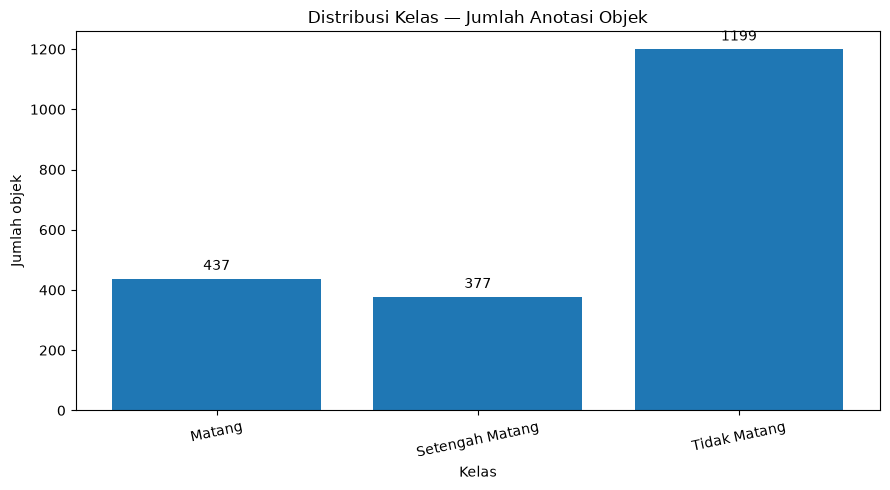

Rasio kelas terbanyak : tersedikit = 3.18


In [11]:
# 3a Distribusi label — analisis per objek (bukan hitung file gambar)
counts=object_df['label'].value_counts().reindex(class_names)
class_table=pd.DataFrame({'kelas':counts.index,'jumlah_objek':counts.values,
                          'persen':(100*counts/counts.sum()).round(2).values})
display(class_table)
class_table.to_csv(OUTPUT/'eda_distribusi_label.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
bars=ax.bar(counts.index,counts.values)
ax.bar_label(bars,padding=4)
ax.set(title='Distribusi Kelas — Jumlah Anotasi Objek',xlabel='Kelas',ylabel='Jumlah objek')
plt.xticks(rotation=12);plt.tight_layout()
plt.savefig(OUTPUT/'eda_distribusi_kelas.png',dpi=160);plt.show()
print('Rasio kelas terbanyak : tersedikit =',round(counts.max()/counts.min(),2))

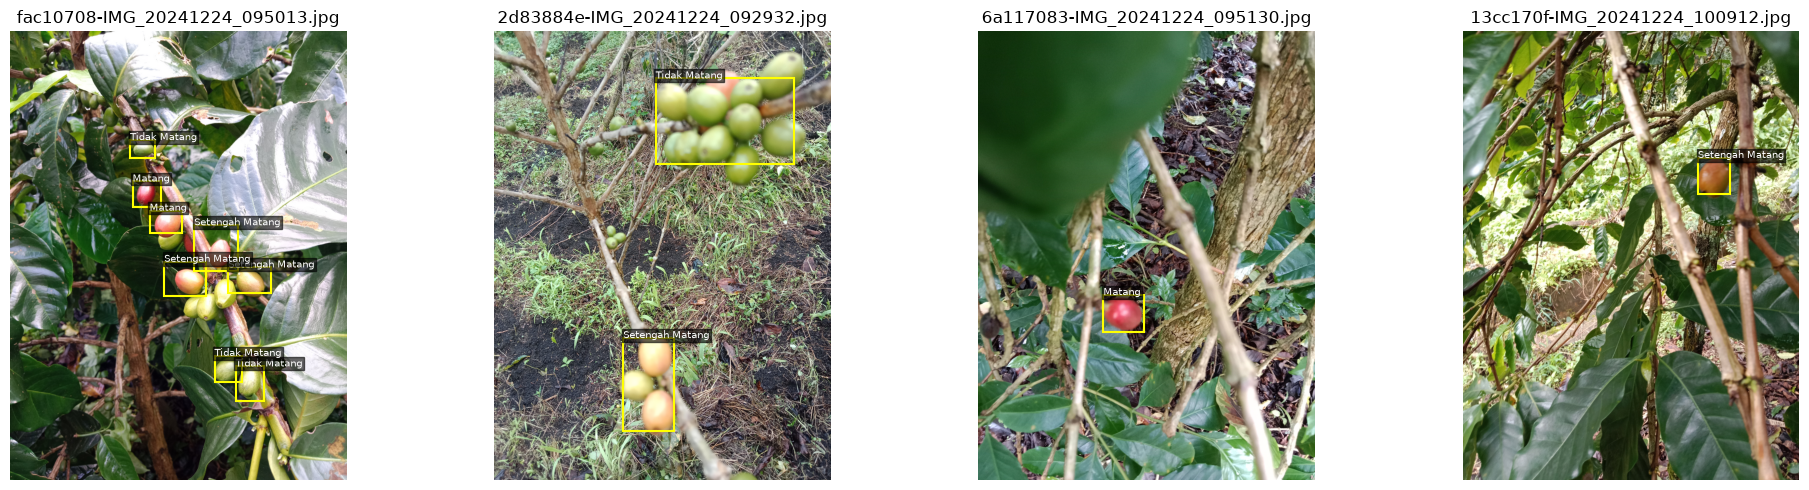

In [12]:
# 3e Gambar asli dengan bounding box + label (contoh EDA)
preview_imgs=object_df['image_path'].drop_duplicates().sample(
    min(4,object_df['image_path'].nunique()),random_state=SEED).tolist()
fig,axes=plt.subplots(1,len(preview_imgs),figsize=(5*len(preview_imgs),5),squeeze=False)
for ax, img_path in zip(axes.ravel(),preview_imgs):
    with Image.open(img_path) as im: image=im.convert('RGB')
    ax.imshow(image)
    for row in object_df.loc[object_df.image_path==img_path].itertuples():
        from matplotlib.patches import Rectangle
        ax.add_patch(Rectangle((row.x1,row.y1),row.x2-row.x1,row.y2-row.y1,
                               fill=False,edgecolor='yellow',linewidth=1.5))
        ax.text(row.x1,row.y1,row.label,color='white',fontsize=7,
                bbox=dict(facecolor='black',alpha=.6,pad=1))
    ax.set_title(Path(img_path).name[:34]); ax.axis('off')
plt.tight_layout();plt.savefig(OUTPUT/'eda_gambar_asli_bbox.png',dpi=160);plt.show()

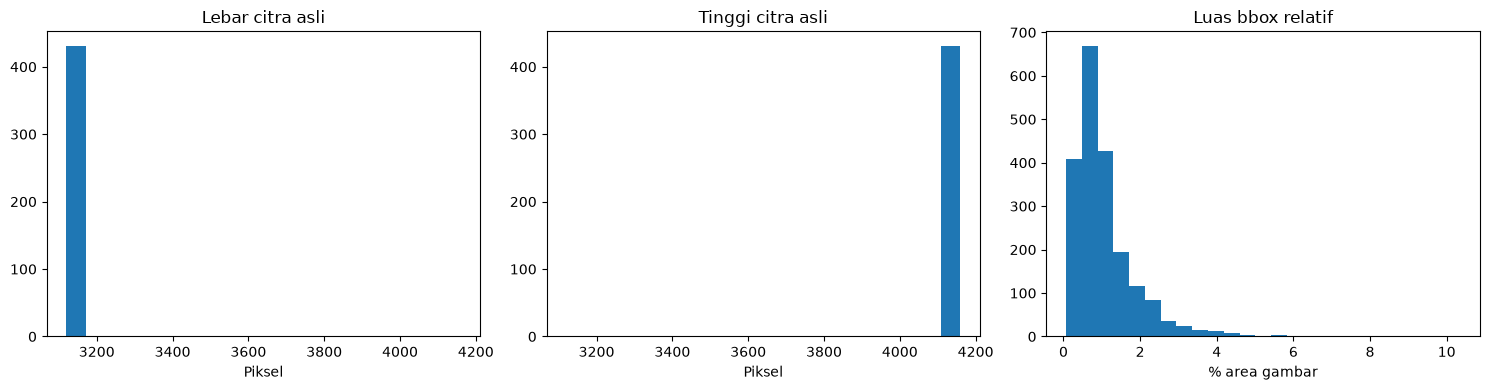

Median persentase luas bounding box: 0.837 %


In [13]:
# Histogram dimensi citra & luas relatif bbox (analisis numerik citra, bukan data tabular biasa)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].hist(unique_photos.width,bins=20);axes[0].set(title='Lebar citra asli',xlabel='Piksel')
axes[1].hist(unique_photos.height,bins=20);axes[1].set(title='Tinggi citra asli',xlabel='Piksel')
areas=(object_df.bbox_area_ratio*100).to_numpy()
if np.isclose(areas.min(),areas.max()):
    axes[2].hist(areas,bins=1,range=(float(areas.min())-0.1,float(areas.max())+0.1))
else:
    axes[2].hist(areas,bins=25)
axes[2].set(title='Luas bbox relatif',xlabel='% area gambar')
plt.tight_layout();plt.savefig(OUTPUT/'eda_resolusi_dan_ukuran_objek.png',dpi=160);plt.show()
print('Median persentase luas bounding box:',round(object_df.bbox_area_ratio.median()*100,3),'%')

**Panduan temuan EDA:**

1. Bila kelas tidak seimbang, pertimbangkan class weight yang dihitung hanya dari training.
2. Bila resolusi berbeda, gunakan *resize with padding* agar bentuk buah tidak terdistorsi.
3. Bila buah kecil dalam foto asli, gunakan crop sesuai bbox dengan margin 10%.
4. Karena kematangan bergantung warna, **hindari augmentasi warna yang ekstrem**.
5. Data lapangan mungkin mengandung occlusion dan perbedaan pencahayaan; bahas pengaruhnya pada hasil akhir.

Semua temuan ini harus dicocokkan dengan grafik aktual, bukan diasumsikan benar tanpa melihat output.

---
# 4. Preprocessing: cropping, resize, normalisasi, augmentasi, dan split anti-kebocoran

**Urutan yang aman:** cleaning foto/anotasi → cropping objek menjadi *crop individual* → split berdasarkan **foto sumber** (`group_sha256`) → pipeline preprocessing/training. Gambar hasil crop dari foto yang sama **tidak boleh muncul di lebih dari satu split**.

**Resize:** 224×224×3 dengan padding. **Normalisasi:** CNN 0..1; MobileNetV2 -1..1 (dilakukan **di dalam model**, sehingga aplikasi menerima piksel 0..255 tanpa normalisasi ganda). **Augmentasi training saja:** flip horizontal, rotasi ±15°, zoom ±10%, kontras ±10%. Tidak ada *random hue* ekstrem karena warna adalah ciri tingkat kematangan.

In [14]:
# Konversi bbox -> crop per buah, dengan margin relatif 10%.
CROP_DIR = DATA_DIR/'crops'
CROP_DIR.mkdir(parents=True,exist_ok=True)
crops, crop_issues=[],[]
for img_path, grp in object_df.groupby('image_path',sort=True):
    try:
        with Image.open(img_path) as image:
            rgb=image.convert('RGB')
            W,H=rgb.size
            for index,row in grp.iterrows():
                bw=row.x2-row.x1; bh=row.y2-row.y1
                x1=max(0,int(np.floor(row.x1-CROP_MARGIN*bw)))
                y1=max(0,int(np.floor(row.y1-CROP_MARGIN*bh)))
                x2=min(W,int(np.ceil(row.x2+CROP_MARGIN*bw)))
                y2=min(H,int(np.ceil(row.y2+CROP_MARGIN*bh)))
                if x2-x1<4 or y2-y1<4:
                    crop_issues.append((img_path,'crop terlalu kecil'));continue
                crop=rgb.crop((x1,y1,x2,y2))
                label=str(row.label)
                folder = CROP_DIR/f'kelas_{int(row.class_id):02d}'
                folder.mkdir(parents=True,exist_ok=True)
                unique_key=hashlib.sha1((img_path+str(index)).encode()).hexdigest()[:18]
                out=folder/f'{unique_key}.jpg'
                if not out.exists(): crop.save(out,format='JPEG',quality=95)
                crops.append({'crop_path':str(out),'image_path':img_path,
                              'group_sha256':row.group_sha256,
                              'label':label,'class_id':int(row.class_id),
                              'crop_width':x2-x1,'crop_height':y2-y1,
                              'bbox_area_ratio':row.bbox_area_ratio})
    except OSError as err:
        crop_issues.append((img_path,str(err)))
crop_df=pd.DataFrame(crops)
assert not crop_df.empty, 'Cropping gagal: tidak ada objek tersimpan.'
print('Crop berhasil:',len(crop_df),'| gagal:',len(crop_issues))
display(crop_df.groupby('label').size().rename('Jumlah crop').to_frame())
crop_df.to_csv(OUTPUT/'metadata_crop.csv',index=False)

Crop berhasil: 2013 | gagal: 0


,Jumlah crop
label,
Matang,437
Setengah Matang,377
Tidak Matang,1199


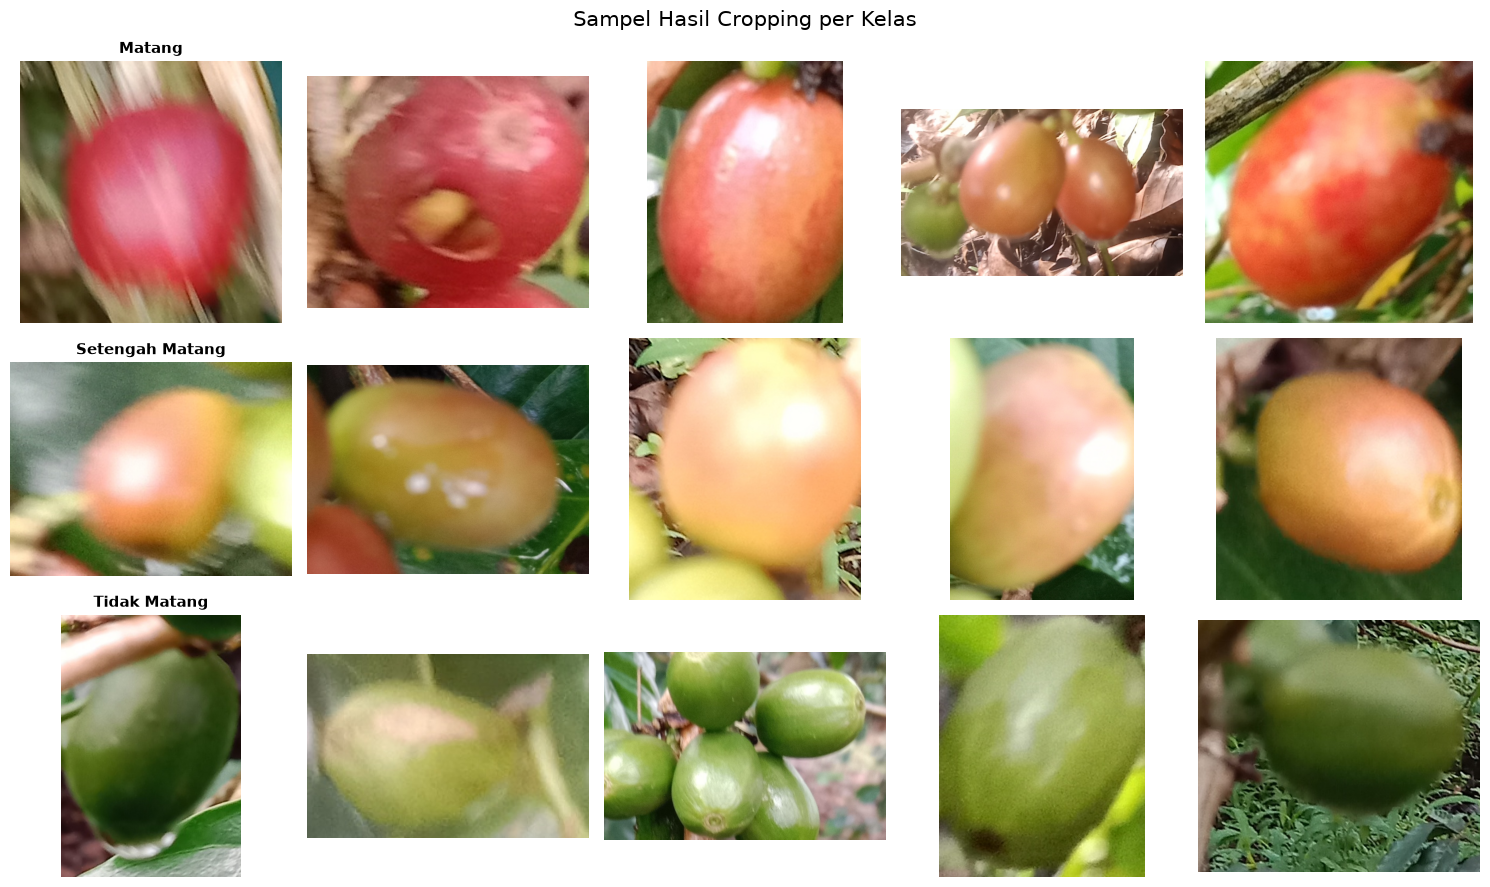

In [15]:
# Menampilkan 5 contoh crop setiap kelas untuk laporan EDA.
N_PER_CLASS = 5
fig,axes=plt.subplots(len(class_names),N_PER_CLASS,
                      figsize=(3.0*N_PER_CLASS,3.0*len(class_names)),squeeze=False)
for i,name in enumerate(class_names):
    subset=crop_df[crop_df.label==name].sample(
        min(N_PER_CLASS,(crop_df.label==name).sum()),random_state=SEED)
    for j,ax in enumerate(axes[i]):
        if j<len(subset):
            with Image.open(subset.iloc[j].crop_path) as im:
                ax.imshow(im.convert('RGB'))
        ax.axis('off')
        if j==0: ax.set_title(name,fontsize=11,fontweight='bold')
plt.suptitle('Sampel Hasil Cropping per Kelas',fontsize=15)
plt.tight_layout();plt.savefig(OUTPUT/'eda_sampel_crop_setiap_kelas.png',dpi=160);plt.show()

## 4.1 Pembagian data 70% / 15% / 15% dengan **group split**

Membagi *foto asli* pada level **grup SHA-256**, bukan secara acak per crop. Karena satu foto memiliki jumlah crop berbeda, proporsi **jumlah crop** dapat sedikit berbeda dari 70:15:15. Code mencoba beberapa seed agar tiap kelas ada pada ketiga split dan proporsi crop mendekati target; tidak menggunakan data testing untuk memilih hyperparameter atau model.

> **Perlu pemeriksaan tambahan:** SHA-256 mendeteksi file identik, bukan near-duplicate dan kesamaan plot/video. Bila ada kode tanaman/lokasi/sesi pengambilan foto, gunakan itu sebagai grup untuk mencegah kebocoran yang lebih ketat.

In [16]:
# Seleksi split menggunakan group-aware split, dengan preferensi semua kelas terwakili.
# Seeding tetap; split tidak dioptimalkan berdasar kinerja model.
def grouped_three_way_split(df, attempts=160):
    X=np.zeros(len(df)); y=df['class_id'].to_numpy(); groups=df['group_sha256'].to_numpy()
    best=None
    for offset in range(attempts):
        g1=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED+offset)
        rest_idx,test_idx=next(g1.split(X,y,groups))
        g2=GroupShuffleSplit(n_splits=1,test_size=.15/.85,random_state=SEED+1000+offset)
        tr_sub, val_sub = next(g2.split(X[rest_idx],y[rest_idx],groups[rest_idx]))
        tr_idx=rest_idx[tr_sub]; val_idx=rest_idx[val_sub]
        parts={'train':tr_idx,'val':val_idx,'test':test_idx}
        class_missing=sum(len(set(class_names)-set(df.iloc[ix]['label'])) for ix in parts.values())
        deviation=sum(abs(len(ix)/len(df)-target) for ix,target in
                      zip([tr_idx,val_idx,test_idx],[.70,.15,.15]))
        # Selisih komposisi kelas tiap split dari distribusi global
        full=np.bincount(y,minlength=len(class_names))/len(y)
        dist_penalty=sum(np.abs(np.bincount(y[ix],minlength=len(class_names))/len(ix)-full).mean()
                         for ix in parts.values() if len(ix))
        score=100*class_missing+deviation+0.5*dist_penalty
        if best is None or score<best[0]: best=(score,parts,class_missing)
    if best[2]:
        raise RuntimeError('Tidak ditemukan pembagian 3 split yang memuat semua kelas. '
                           'Periksa jumlah foto asli per kelas atau revisi proporsi split.')
    return best[1]

split_indices=grouped_three_way_split(crop_df)
crop_df['split']=''
for split,indices in split_indices.items():
    crop_df.loc[indices,'split']=split
assert not (crop_df.split=='').any()
train_df=crop_df[crop_df.split=='train'].copy()
val_df=crop_df[crop_df.split=='val'].copy()
test_df=crop_df[crop_df.split=='test'].copy()
assert set(train_df.group_sha256).isdisjoint(set(val_df.group_sha256))
assert set(train_df.group_sha256).isdisjoint(set(test_df.group_sha256))
assert set(val_df.group_sha256).isdisjoint(set(test_df.group_sha256))
print('Tidak ada overlap group antara train/val/test: ✅')
split_table=pd.crosstab(crop_df['label'],crop_df['split']).reindex(columns=['train','val','test'])
display(split_table)
print('Proporsi crop (%)', (crop_df.split.value_counts(normalize=True).reindex(['train','val','test'])*100).round(2).to_dict())
print('Jumlah foto unik per split:',crop_df.groupby('split')['group_sha256'].nunique().to_dict())
split_table.to_csv(OUTPUT/'tabel_distribusi_split.csv')
crop_df.to_csv(OUTPUT/'metadata_crop_dengan_split.csv',index=False)

Tidak ada overlap group antara train/val/test: ✅


split,train,val,test
label,,,
Matang,309,65,63
Setengah Matang,254,59,64
Tidak Matang,841,183,175


Proporsi crop (%) {'train': 69.75, 'val': 15.25, 'test': 15.0}
Jumlah foto unik per split: {'test': 65, 'train': 302, 'val': 65}


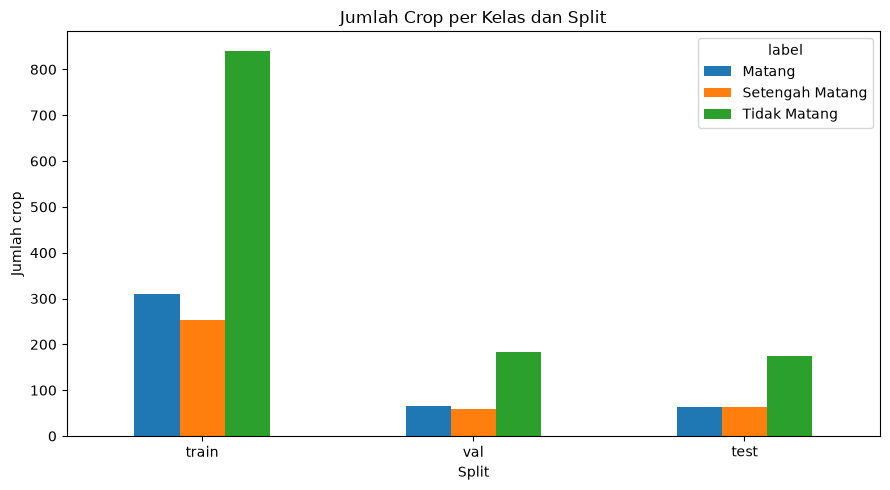

In [17]:
# Visualisasi distribusi kelas setiap split
ax=split_table.T.plot(kind='bar',figsize=(9,5),rot=0)
ax.set(title='Jumlah Crop per Kelas dan Split',xlabel='Split',ylabel='Jumlah crop')
plt.tight_layout();plt.savefig(OUTPUT/'preprocessing_distribusi_split.png',dpi=160);plt.show()

## 4.2 Dataset TensorFlow `tf.data` + augmentasi

- File dibaca dalam **RGB**; resize dengan `tf.image.resize_with_pad()`; output `float32` masih pada skala **0–255**.
- Layer normalisasi berada dalam masing-masing model untuk menghindari **double normalization**.
- Augmentasi berada dalam model dan otomatis hanya aktif saat `training=True`, jadi **validation/testing bersih**.
- Jika ada imbalance, `class_weight` dibuat dari **training split saja**. Penggunaan dapat dinyalakan/matikan sesuai EDA.

In [18]:
AUTOTUNE=tf.data.AUTOTUNE

def read_and_resize(path, label):
    raw=tf.io.read_file(path)
    img=tf.io.decode_image(raw,channels=3,expand_animations=False)
    img.set_shape([None,None,3])
    img=tf.image.resize_with_pad(img,IMG_SIZE[0],IMG_SIZE[1],method='bilinear')
    img=tf.ensure_shape(img,[*IMG_SIZE,3])
    return img, tf.cast(label,tf.int32)

def make_dataset(df, training=False):
    ds=tf.data.Dataset.from_tensor_slices((df.crop_path.to_numpy(),df.class_id.to_numpy(np.int32)))
    if training: ds=ds.shuffle(len(df),seed=SEED,reshuffle_each_iteration=True)
    return ds.map(read_and_resize,num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds=make_dataset(train_df,training=True)
train_eval_ds=make_dataset(train_df,training=False)
val_ds=make_dataset(val_df)
test_ds=make_dataset(test_df)

# Aturan sederhana: aktifkan class weighting jika ketimpangan kelas > 1.5x.
counts_train=train_df.class_id.value_counts().reindex(range(len(class_names)),fill_value=0)
ratio=float(counts_train.max()/max(counts_train.min(),1))
USE_CLASS_WEIGHT = ratio > 1.5
class_weight={i:len(train_df)/(len(class_names)*int(counts_train[i]))
              for i in range(len(class_names))}
print('Rasio kelas TRAIN:',round(ratio,2),'| Pakai class weighting?',USE_CLASS_WEIGHT)
print('Class weight:',class_weight if USE_CLASS_WEIGHT else 'Tidak digunakan')
print('Shape satu batch:',next(iter(train_ds))[0].shape)

Rasio kelas TRAIN: 3.31 | Pakai class weighting? True
Class weight: {0: 1.5145631067961165, 1: 1.8425196850393701, 2: 0.5564803804994055}
Shape satu batch: (32, 224, 224, 3)


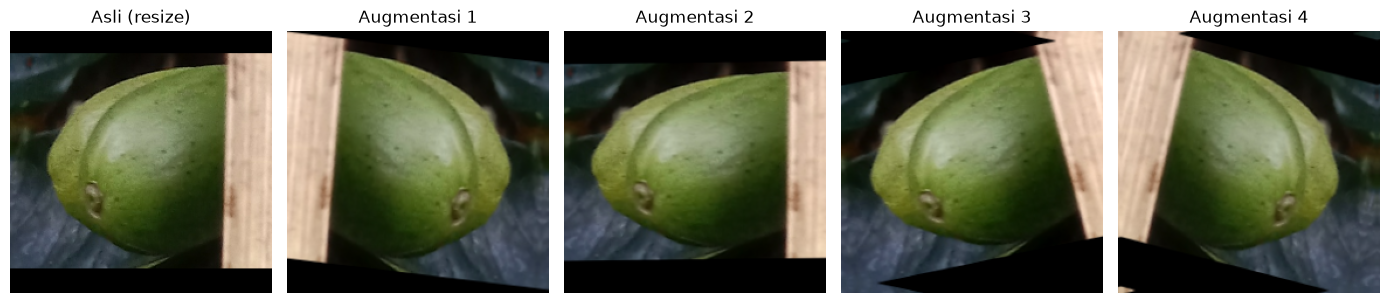

In [19]:
# Contoh augmentasi yang benar-benar akan digunakan dalam training
# rotasi 15° = 15/360 pada parameter RandomRotation.
from tensorflow.keras import layers, models

def make_augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal',seed=SEED),
        layers.RandomRotation(factor=15/360,fill_mode='reflect',seed=SEED),
        layers.RandomZoom(height_factor=(-0.10,0.10),
                          width_factor=(-0.10,0.10),fill_mode='reflect',seed=SEED),
        layers.RandomContrast(factor=0.10,seed=SEED),
    ],name='augmentasi_training')

example_batch,_=next(iter(train_eval_ds))
example=example_batch[0:1]
aug_preview=make_augmentation()
fig,axs=plt.subplots(1,5,figsize=(14,3))
axs[0].imshow(np.clip(example[0].numpy()/255,0,1));axs[0].set_title('Asli (resize)')
for j in range(1,5):
    modified=aug_preview(example,training=True)[0].numpy()
    axs[j].imshow(np.clip(modified/255,0,1));axs[j].set_title('Augmentasi '+str(j))
for ax in axs:ax.axis('off')
plt.tight_layout();plt.savefig(OUTPUT/'preprocessing_contoh_augmentasi.png',dpi=160);plt.show()

---
# 5. Model CNN Custom (ketentuan 5a–5d)

**Mengapa CNN custom?** Menjadi baseline yang mempelajari fitur visual buah kopi dari nol dengan arsitektur sederhana dan mudah dijelaskan. Terdiri atas **3 Conv2D**, **3 MaxPooling**, **GlobalAveragePooling**, **Dense 128**, **Dropout 0.5**, dan **Softmax K kelas**. Lapisan augmentasi dan rescaling ada pada alur input. `GlobalAveragePooling2D` dipilih daripada `Flatten` untuk mengurangi parameter.

**Konfigurasi awal:** Adam LR `1e-3`, batch 32, maksimum 30 epoch, sparse categorical cross-entropy, early stopping patience 5, checkpoint, reduksi learning rate. Jumlah parameter dan ukuran keluaran dihitung otomatis.

In [20]:
num_classes=len(class_names)

def build_cnn():
    inp=layers.Input(shape=(*IMG_SIZE,3),name='image_0_255')
    x=make_augmentation()(inp)
    x=layers.Rescaling(1/255,name='rescale_cnn_0_1')(x)
    for nfilters in [32,64,128]:
        x=layers.Conv2D(nfilters,3,padding='same',activation='relu',
                        name=f'conv_{nfilters}')(x)
        x=layers.MaxPooling2D(name=f'pool_{nfilters}')(x)
    x=layers.Activation('linear',name='feature_maps')(x)  # untuk Grad-CAM
    x=layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
    x=layers.Dense(128,activation='relu',name='dense_128')(x)
    x=layers.Dropout(.5,name='dropout_05')(x)
    out=layers.Dense(num_classes,activation='softmax',name='kelas_softmax')(x)
    model=tf.keras.Model(inp,out,name='CNN_Custom')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model

cnn=build_cnn()
cnn.summary()
print('Jumlah parameter CNN:',cnn.count_params())

Model: "CNN_Custom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_255 (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi_training             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_cnn_0_1 (Rescaling)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_32 (Conv2D)                │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_32 (MaxPooling2D)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_64 (Conv2D)                │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_64 (MaxPooling2D)          │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_128 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_128 (MaxPooling2D)         │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_maps (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_05 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ kelas_softmax (Dense)           │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

Jumlah parameter CNN: 110147


In [21]:
# Diagram arsitektur otomatis; bila graphviz tidak tersedia, teks summary tetap lengkap.
def save_architecture_diagram(model, filename):
    try:
        tf.keras.utils.plot_model(model,to_file=str(OUTPUT/filename),
                                  show_shapes=True,show_layer_names=True,
                                  show_layer_activations=True,rankdir='TB',dpi=95)
        print('Diagram tersimpan:',OUTPUT/filename)
        display(Image.open(OUTPUT/filename))
    except Exception as err:
        print('Diagram otomatis tak tersedia (butuh graphviz/pydot):',str(err)[:250])
        print('Gunakan model.summary() sebagai bukti arsitektur.')

save_architecture_diagram(cnn,'arsitektur_cnn.png')

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagram tersimpan: d:\DevOps\coffee_cherry\coffee_cherry_dl\hasil\arsitektur_cnn.png
Diagram otomatis tak tersedia (butuh graphviz/pydot): [Errno 2] No such file or directory: 'd:\\DevOps\\coffee_cherry\\coffee_cherry_dl\\hasil\\arsitektur_cnn.png'
Gunakan model.summary() sebagai bukti arsitektur.


Epoch 1/5


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


44/44 ━━━━━━━━━━━━━━━━━━━━ 68s 1s/step - accuracy: 0.6538 - loss: 0.7916 - val_accuracy: 0.9023 - val_loss: 0.3233 - learning_rate: 0.0010
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 68s 2s/step - accuracy: 0.8298 - loss: 0.5277 - val_accuracy: 0.9283 - val_loss: 0.3443 - learning_rate: 0.0010
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.8761 - loss: 0.4231 - val_accuracy: 0.9251 - val_loss: 0.2257 - learning_rate: 0.0010
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.8818 - loss: 0.3671 - val_accuracy: 0.8274 - val_loss: 0.4309 - learning_rate: 0.0010
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.8882 - loss: 0.4051 - val_accuracy: 0.9479 - val_loss: 0.1839 - learning_rate: 0.0010


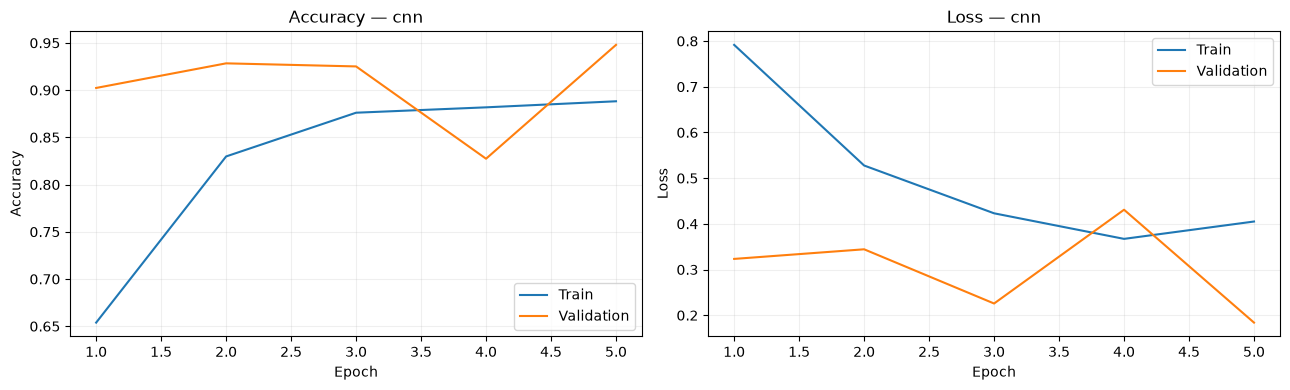

Waktu training CNN (detik): 318.93


In [22]:
# Callback pelatihan dan plotting kurva
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

def callbacks_for(model_name):
    return [
        EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
        ModelCheckpoint(str(MODEL_DIR/f'{model_name}.keras'),monitor='val_loss',
                        save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3,min_lr=1e-6)
    ]

def plot_history(history,label):
    h=pd.DataFrame(history.history)
    h.index=h.index+1
    h.index.name='epoch'
    h.to_csv(OUTPUT/f'training_history_{label}.csv')
    fig,ax=plt.subplots(1,2,figsize=(13,4))
    ax[0].plot(h.index,h['accuracy'],label='Train')
    ax[0].plot(h.index,h['val_accuracy'],label='Validation')
    ax[0].set(xlabel='Epoch',ylabel='Accuracy',title=f'Accuracy — {label}')
    ax[1].plot(h.index,h['loss'],label='Train')
    ax[1].plot(h.index,h['val_loss'],label='Validation')
    ax[1].set(xlabel='Epoch',ylabel='Loss',title=f'Loss — {label}')
    for a in ax:a.legend();a.grid(alpha=.2)
    plt.tight_layout();plt.savefig(OUTPUT/f'kurva_{label}.png',dpi=160);plt.show()
    return h

start=time.perf_counter()
cnn_history=cnn.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_CNN,
                    callbacks=callbacks_for('cnn_custom'),
                    class_weight=class_weight if USE_CLASS_WEIGHT else None,verbose=1)
cnn_seconds=time.perf_counter()-start
cnn=tf.keras.models.load_model(MODEL_DIR/'cnn_custom.keras')
cnn_hist_df=plot_history(cnn_history,'cnn')
print('Waktu training CNN (detik):',round(cnn_seconds,2))

---
# 6. Transfer Learning MobileNetV2 (ketentuan 5a–5d)

**Mengapa MobileNetV2?** Backbone CNN ringan dengan bobot **ImageNet** untuk mentransfer representasi visual umum ke dataset buah kopi. **Tahap ini membekukan backbone**; hanya *classification head* yang dilatih. Ini perbandingan yang mudah dijelaskan terhadap CNN dari nol. Fine-tuning backbone dapat ditambahkan di luar ruang lingkup tugas.

**Konfigurasi awal:** `MobileNetV2(include_top=False, weights='imagenet')`, output fitur 7×7×1280 untuk input 224×224, GAP → Dense 128/ReLU → Dropout 0.3 → Softmax K, Adam LR `1e-4`, batch 32, maksimum 30 epoch, early stopping patience 5.

In [23]:
def build_mobilenet():
    inp=layers.Input(shape=(*IMG_SIZE,3),name='image_0_255')
    x=make_augmentation()(inp)
    # Ekuivalen preprocess_input MobileNetV2: pixel mentah 0..255 -> [-1,1].
    x=layers.Rescaling(1/127.5,offset=-1,name='mobilenet_preprocess_minus1_1')(x)
    try:
        backbone=tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE,3),
                            include_top=False,weights='imagenet')
    except Exception as err:
        raise RuntimeError('Bobot ImageNet gagal diunduh. Pastikan Colab terhubung internet. '
                           'Jangan menggantinya dengan weights=None tanpa menjelaskan '
                           'bahwa itu BUKAN transfer learning.') from err
    backbone.trainable=False
    x=backbone(x,training=False)
    x=layers.Activation('linear',name='feature_maps')(x)
    x=layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
    x=layers.Dense(128,activation='relu',name='dense_128')(x)
    x=layers.Dropout(.3,name='dropout_03')(x)
    out=layers.Dense(num_classes,activation='softmax',name='kelas_softmax')(x)
    model=tf.keras.Model(inp,out,name='MobileNetV2_TransferLearning')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model

mobilenet=build_mobilenet()
mobilenet.summary()
print('Total parameter MobileNetV2:',mobilenet.count_params())
print('Trainable parameter:',sum(int(np.prod(w.shape)) for w in mobilenet.trainable_weights))
print('Non-trainable parameter:',sum(int(np.prod(w.shape)) for w in mobilenet.non_trainable_weights))

Model: "MobileNetV2_TransferLearning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_255 (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi_training             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess_minus1_1   │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_maps (Activation)       │ (None, 7, 7, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_03 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ kelas_softmax (Dense)           │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameter MobileNetV2: 2422339
Trainable parameter: 164355
Non-trainable parameter: 2257984


In [24]:
save_architecture_diagram(mobilenet,'arsitektur_mobilenetv2.png')

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagram tersimpan: d:\DevOps\coffee_cherry\coffee_cherry_dl\hasil\arsitektur_mobilenetv2.png
Diagram otomatis tak tersedia (butuh graphviz/pydot): [Errno 2] No such file or directory: 'd:\\DevOps\\coffee_cherry\\coffee_cherry_dl\\hasil\\arsitektur_mobilenetv2.png'
Gunakan model.summary() sebagai bukti arsitektur.


Epoch 1/5


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


44/44 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.6097 - loss: 0.9412 - val_accuracy: 0.8274 - val_loss: 0.5471 - learning_rate: 1.0000e-04
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.8276 - loss: 0.5184 - val_accuracy: 0.8762 - val_loss: 0.3763 - learning_rate: 1.0000e-04
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 851ms/step - accuracy: 0.8761 - loss: 0.4011 - val_accuracy: 0.8958 - val_loss: 0.3335 - learning_rate: 1.0000e-04
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 824ms/step - accuracy: 0.8896 - loss: 0.3447 - val_accuracy: 0.9153 - val_loss: 0.2843 - learning_rate: 1.0000e-04
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9103 - loss: 0.3013 - val_accuracy: 0.9218 - val_loss: 0.2362 - learning_rate: 1.0000e-04


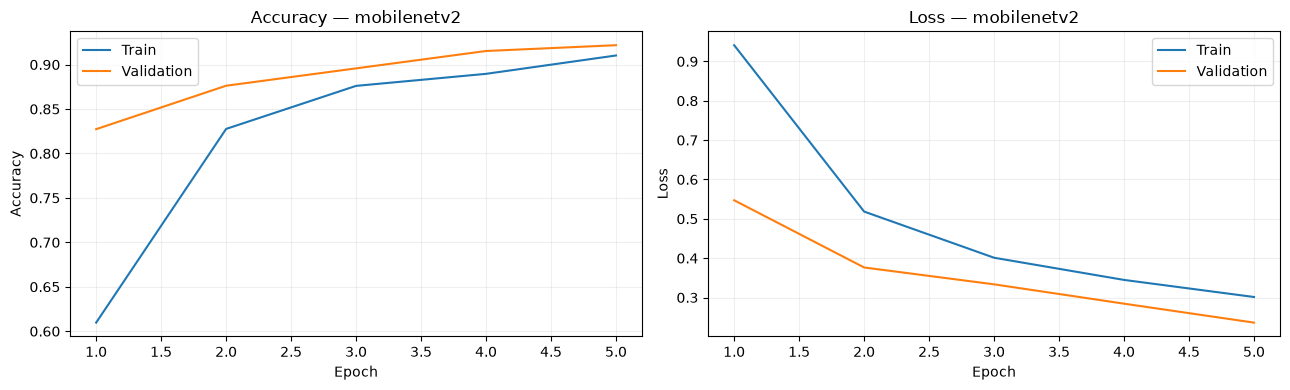

Waktu training MobileNetV2 (detik): 240.68


In [25]:
start=time.perf_counter()
mobile_history=mobilenet.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_MOBILENET,
                            callbacks=callbacks_for('mobilenetv2'),
                            class_weight=class_weight if USE_CLASS_WEIGHT else None,verbose=1)
mobile_seconds=time.perf_counter()-start
mobilenet=tf.keras.models.load_model(MODEL_DIR/'mobilenetv2.keras')
mobile_hist_df=plot_history(mobile_history,'mobilenetv2')
print('Waktu training MobileNetV2 (detik):',round(mobile_seconds,2))

---
# 7. Hasil evaluasi dan perbandingan model (ketentuan 6a–6e)

**Metrik utama:** macro F1 (setiap kelas memiliki bobot sama). **Metrik lain:** accuracy, macro precision, macro recall, serta confusion matrix untuk mengetahui kelas yang sering tertukar.

**Protokol yang benar:** gunakan **validation** untuk memilih model terbaik dan menetapkan threshold. **Test** digunakan untuk pelaporan final; **jangan** mengubah model/hyperparameter setelah melihat test. Nilai metrik dari notebook ini berasal dari prediksi nyata, bukan contoh sintetis.

In [26]:
# Prediksi probabilitas. Validation dipakai memilih model terbaik.
def predict_probs(model, ds):
    arr=model.predict(ds,verbose=0)
    assert arr.ndim==2 and arr.shape[1]==num_classes
    assert np.all(np.isfinite(arr))
    return arr

def summarize_metrics(y_true, probs):
    labels=probs.argmax(axis=1)
    pr,re,f1,_=precision_recall_fscore_support(y_true,labels,
                                average='macro',zero_division=0)
    return {'accuracy':accuracy_score(y_true,labels),
            'precision_macro':pr,'recall_macro':re,'f1_macro':f1}

y_val=val_df.class_id.to_numpy()
y_test=test_df.class_id.to_numpy()
val_probs_cnn=predict_probs(cnn,val_ds)
val_probs_mobile=predict_probs(mobilenet,val_ds)
val_scores=pd.DataFrame([
    dict(model='CNN Custom',**summarize_metrics(y_val,val_probs_cnn)),
    dict(model='MobileNetV2',**summarize_metrics(y_val,val_probs_mobile))
]).set_index('model')
display(val_scores.round(4))
val_scores.to_csv(OUTPUT/'evaluasi_validation_pemilihan_model.csv')
selected_name=val_scores['f1_macro'].idxmax()
selected_model=cnn if selected_name=='CNN Custom' else mobilenet
selected_val_probs=val_probs_cnn if selected_name=='CNN Custom' else val_probs_mobile
print('MODEL TERPILIH BERDASARKAN F1 MACRO VALIDATION:',selected_name)
selected_model.save(MODEL_DIR/'best_model.keras')

,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
CNN Custom,0.9479,0.9260,0.9286,0.9265
MobileNetV2,0.9218,0.8836,0.8889,0.8834


MODEL TERPILIH BERDASARKAN F1 MACRO VALIDATION: CNN Custom


,waktu_train_detik,parameters,accuracy,precision_macro,recall_macro,f1_macro
model,,,,,,
CNN Custom,318.9255,110147,0.9437,0.9205,0.9376,0.9281
MobileNetV2,240.6765,2422339,0.9007,0.8661,0.8898,0.8766



--- Classification Report: cnn ---
                 precision    recall  f1-score   support

         Matang       0.94      0.94      0.94        63
Setengah Matang       0.83      0.92      0.87        64
   Tidak Matang       0.99      0.95      0.97       175

       accuracy                           0.94       302
      macro avg       0.92      0.94      0.93       302
   weighted avg       0.95      0.94      0.94       302



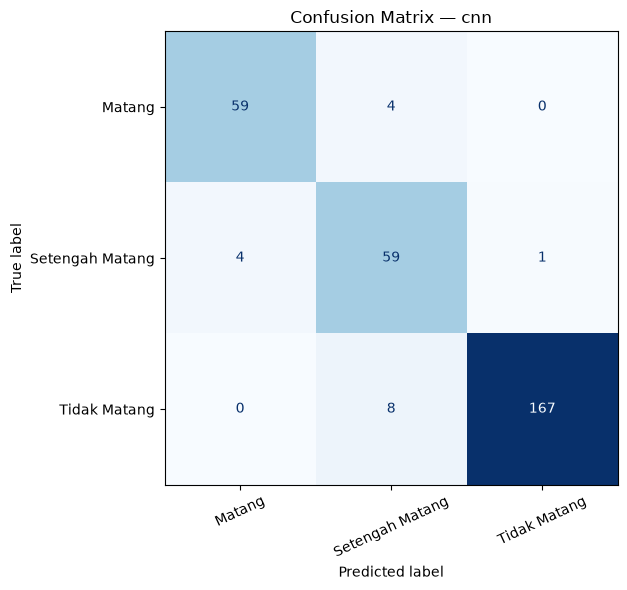


--- Classification Report: mobilenetv2 ---
                 precision    recall  f1-score   support

         Matang       0.86      0.97      0.91        63
Setengah Matang       0.77      0.78      0.78        64
   Tidak Matang       0.97      0.92      0.94       175

       accuracy                           0.90       302
      macro avg       0.87      0.89      0.88       302
   weighted avg       0.90      0.90      0.90       302



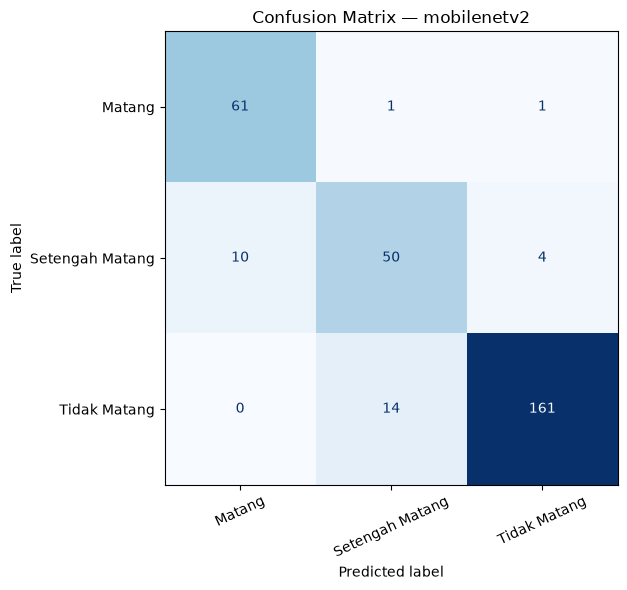

In [27]:
# TEST FINAL: gunakan split yang benar-benar ditahan dari training dan pemilihan.
test_probs_cnn=predict_probs(cnn,test_ds)
test_probs_mobile=predict_probs(mobilenet,test_ds)
test_scores=pd.DataFrame([
    dict(model='CNN Custom',waktu_train_detik=cnn_seconds,parameters=cnn.count_params(),
         **summarize_metrics(y_test,test_probs_cnn)),
    dict(model='MobileNetV2',waktu_train_detik=mobile_seconds,parameters=mobilenet.count_params(),
         **summarize_metrics(y_test,test_probs_mobile))
]).set_index('model')
display(test_scores.round(4))
test_scores.to_csv(OUTPUT/'evaluasi_testing_perbandingan_model.csv')

for label,probs in [('cnn',test_probs_cnn),('mobilenetv2',test_probs_mobile)]:
    preds=probs.argmax(axis=1)
    print(f'\n--- Classification Report: {label} ---')
    report=classification_report(y_test,preds,labels=list(range(num_classes)),
                                target_names=class_names,zero_division=0)
    print(report)
    (OUTPUT/f'classification_report_{label}.txt').write_text(report,encoding='utf-8')
    cm=confusion_matrix(y_test,preds,labels=list(range(num_classes)))
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,cmap='Blues',
                        colorbar=False,values_format='d',xticks_rotation=25)
    ax.set_title(f'Confusion Matrix — {label}')
    plt.tight_layout();plt.savefig(OUTPUT/f'confusion_matrix_{label}.png',dpi=160);plt.show()

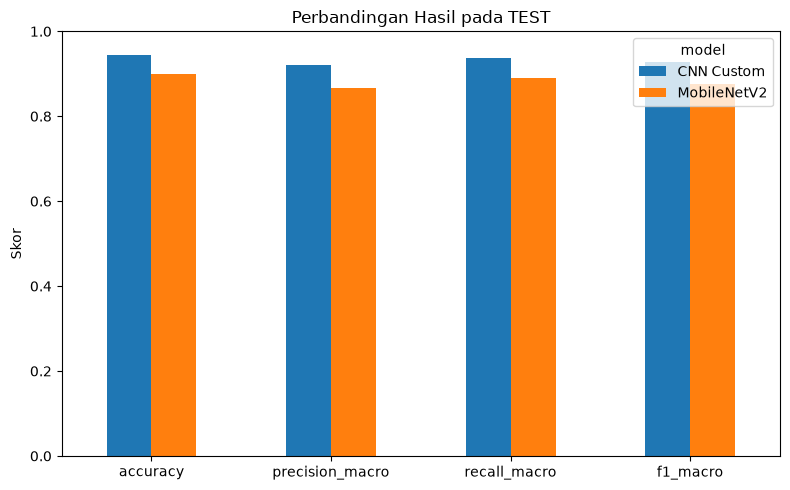

CNN Custom: epoch terbaik (val_loss)=5, train_acc=0.888, val_acc=0.948, gap=-0.060
MobileNetV2: epoch terbaik (val_loss)=5, train_acc=0.910, val_acc=0.922, gap=-0.012


,model,epoch_val_loss_terbaik,akurasi_train_pada_epoch_terbaik,akurasi_val_pada_epoch_terbaik,gap_train_minus_val
0,CNN Custom,5,0.888,0.948,-0.060
1,MobileNetV2,5,0.910,0.922,-0.012


Interpretasi: gap training-validation yang besar bisa menandakan overfitting; akurasi keduanya rendah bisa menandakan underfitting. Periksa juga kurva loss.


In [28]:
# Perbandingan visual & analisis overfitting/underfitting secara kuantitatif
fig,ax=plt.subplots(figsize=(8,5))
metrics=['accuracy','precision_macro','recall_macro','f1_macro']
test_scores[metrics].T.plot(kind='bar',ax=ax,rot=0)
ax.set(ylabel='Skor',ylim=(0,1),title='Perbandingan Hasil pada TEST')
plt.tight_layout();plt.savefig(OUTPUT/'perbandingan_model_testing.png',dpi=160);plt.show()

def training_diagnosis(history_df, name):
    ix=history_df['val_loss'].idxmin()
    row=history_df.loc[ix]
    gap=float(row['accuracy']-row['val_accuracy'])
    print(f'{name}: epoch terbaik (val_loss)={ix}, train_acc={row["accuracy"]:.3f}, '
          f'val_acc={row["val_accuracy"]:.3f}, gap={gap:+.3f}')
    return {'model':name,'epoch_val_loss_terbaik':int(ix),
            'akurasi_train_pada_epoch_terbaik':float(row['accuracy']),
            'akurasi_val_pada_epoch_terbaik':float(row['val_accuracy']),
            'gap_train_minus_val':gap}

diagnosis_df=pd.DataFrame([training_diagnosis(cnn_hist_df,'CNN Custom'),
                           training_diagnosis(mobile_hist_df,'MobileNetV2')])
display(diagnosis_df.round(3))
diagnosis_df.to_csv(OUTPUT/'analisis_generalization_gap.csv',index=False)
print('Interpretasi: gap training-validation yang besar bisa menandakan overfitting; '
      'akurasi keduanya rendah bisa menandakan underfitting. Periksa juga kurva loss.')

Jumlah salah prediksi: 17 dari 302


jumlah
label           predicted_label        
Tidak Matang    Setengah Matang       8
Matang          Setengah Matang       4
Setengah Matang Matang                4
                Tidak Matang          1

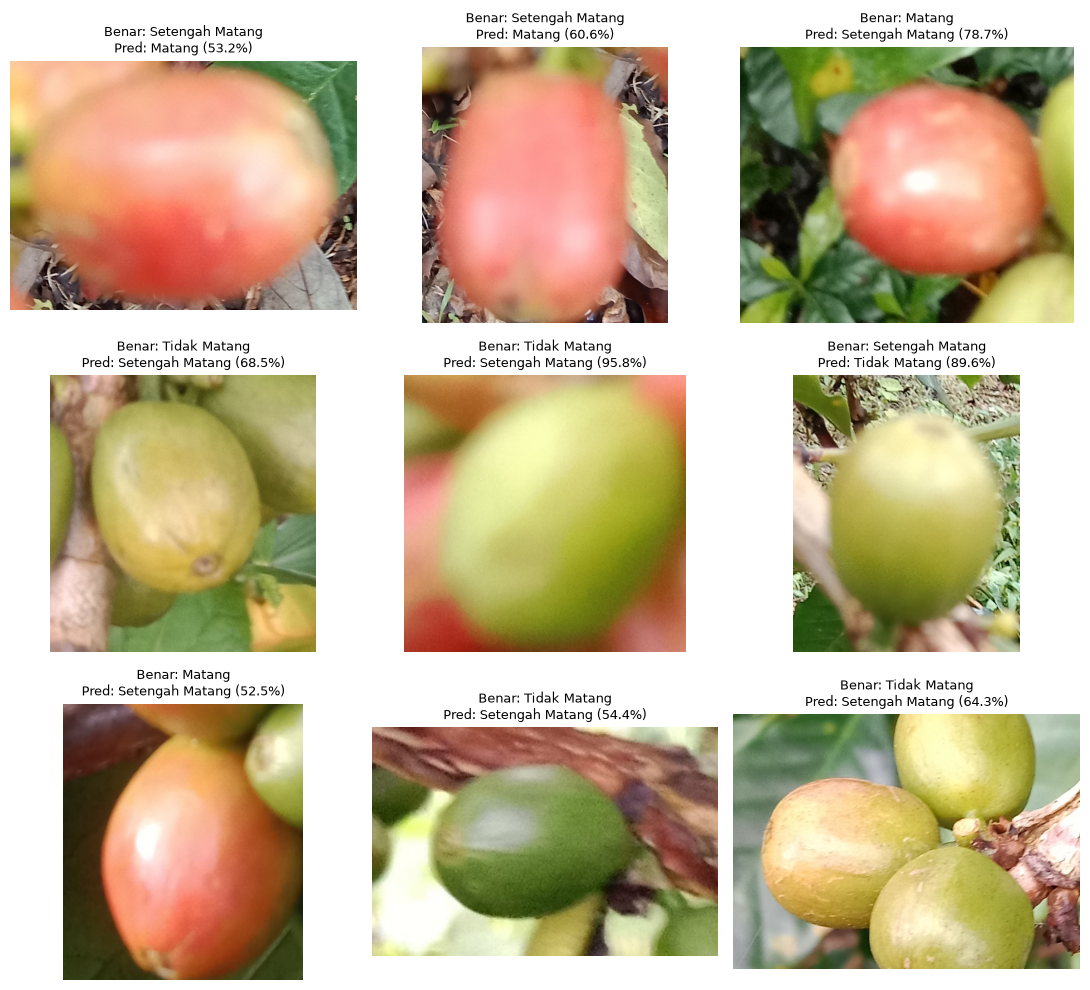

In [29]:
# Analisis kesalahan per kelas pada model TERPILIH.
selected_test_probs=test_probs_cnn if selected_name=='CNN Custom' else test_probs_mobile
selected_preds=selected_test_probs.argmax(axis=1)
errors_df=test_df.copy().reset_index(drop=True)
errors_df['predicted_id']=selected_preds
errors_df['predicted_label']=[idx_to_class[int(p)] for p in selected_preds]
errors_df['confidence']=selected_test_probs.max(axis=1)
errors_df['correct']=errors_df.class_id==errors_df.predicted_id
wrong=errors_df[~errors_df.correct]
print('Jumlah salah prediksi:',len(wrong),'dari',len(errors_df))
if len(wrong):
    display(wrong.groupby(['label','predicted_label']).size()
            .sort_values(ascending=False).rename('jumlah').to_frame().head(12))
    shown=wrong.head(9)
    fig,ax=plt.subplots(3,3,figsize=(11,10))
    for a in ax.ravel():a.axis('off')
    for a,row in zip(ax.ravel(),shown.itertuples()):
        with Image.open(row.crop_path) as im:a.imshow(im.convert('RGB'))
        a.set_title(f'Benar: {row.label}\nPred: {row.predicted_label} ({row.confidence:.1%})',fontsize=9)
    plt.tight_layout();plt.savefig(OUTPUT/'analisis_prediksi_salah.png',dpi=160);plt.show()
else:
    print('Tidak ada prediksi salah pada sampel test. Tetap bahas keterbatasan dataset.')
errors_df.to_csv(OUTPUT/'detail_prediksi_test_model_terpilih.csv',index=False)

---
# 8. Fitur unik #1 — Grad-CAM (ketentuan 5e)

**Apa?** Visualisasi heatmap untuk memperlihatkan area spasial yang berkontribusi pada prediksi model CNN.  
**Mengapa?** Pada citra buah kopi, model seharusnya memperhatikan buah, **bukan daun/latar**.  
**Bagaimana?** Hitung gradien skor kelas terhadap aktivasi spasial `feature_maps`, bobotkan feature map dengan rata-rata gradien, lalu overlay pada gambar.  
**Bukti dampak:** contoh prediksi benar dan salah dengan heatmap serta interpretasi apakah fokus model relevan. **Grad-CAM tidak meningkatkan accuracy secara otomatis**, tetapi meningkatkan interpretabilitas.

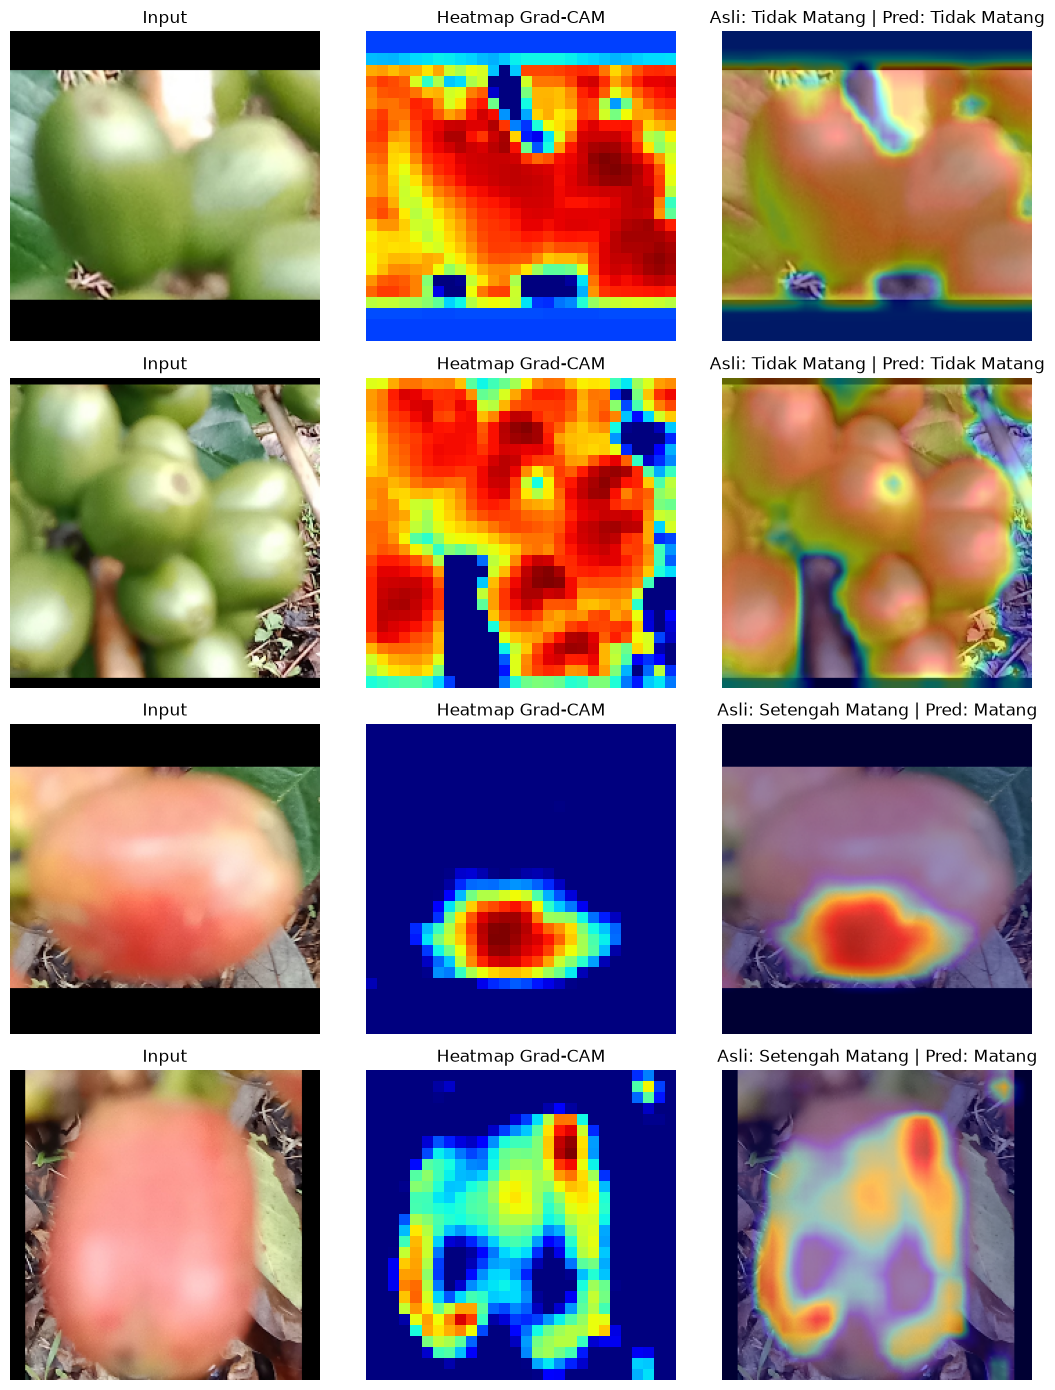

In [30]:
# Grad-CAM dari feature_maps model terpilih (berfungsi untuk CNN dan MobileNetV2).
import matplotlib.cm as cm

def preprocess_single_pil(pil_image):
    rgb=pil_image.convert('RGB')
    arr=np.asarray(rgb,dtype=np.uint8)
    t=tf.image.resize_with_pad(tf.convert_to_tensor(arr),*IMG_SIZE)
    return tf.expand_dims(tf.cast(t,tf.float32),0)

def gradcam_heatmap(model,input_tensor,class_index=None):
    feature_layer=model.get_layer('feature_maps')
    grad_model=tf.keras.Model(model.inputs,[feature_layer.output,model.output])
    with tf.GradientTape() as tape:
        activations,preds=grad_model(input_tensor,training=False)
        if class_index is None:
            class_index=int(tf.argmax(preds[0]))
        score=preds[:,class_index]
    grads=tape.gradient(score,activations)
    if grads is None:
        raise RuntimeError('Gradien Grad-CAM kosong; periksa graph feature_maps.')
    weights=tf.reduce_mean(grads,axis=(0,1,2))
    raw=tf.reduce_sum(activations[0]*weights,axis=-1)
    raw=tf.nn.relu(raw)
    denom=tf.reduce_max(raw)
    heat=raw/(denom+tf.keras.backend.epsilon())
    return heat.numpy(),class_index

def overlay_heatmap(batch_image,heatmap,alpha=.40):
    base=np.uint8(np.clip(batch_image,0,255))
    res=cv2.resize(heatmap,(base.shape[1],base.shape[0]))
    color=cv2.applyColorMap(np.uint8(res*255),cv2.COLORMAP_JET)
    color=cv2.cvtColor(color,cv2.COLOR_BGR2RGB)
    return np.uint8((1-alpha)*base+alpha*color)

# Cari contoh prediksi benar/salah dari test (tanpa melatih ulang).
show_indices=list(np.flatnonzero(errors_df.correct.to_numpy())[:2]) + list(np.flatnonzero(~errors_df.correct.to_numpy())[:2])
if not show_indices: show_indices=[0]
fig,axs=plt.subplots(len(show_indices),3,figsize=(11,3.5*len(show_indices)),squeeze=False)
for r,idx in enumerate(show_indices):
    row=errors_df.iloc[idx]
    with Image.open(row.crop_path) as im: batch=preprocess_single_pil(im)
    heat,class_idx=gradcam_heatmap(selected_model,batch)
    image=batch.numpy()[0]
    axs[r,0].imshow(np.uint8(np.clip(image,0,255)))
    axs[r,0].set_title('Input')
    axs[r,1].imshow(heat,cmap='jet',vmin=0,vmax=1)
    axs[r,1].set_title('Heatmap Grad-CAM')
    axs[r,2].imshow(overlay_heatmap(image,heat))
    axs[r,2].set_title(f'Asli: {row.label} | Pred: {row.predicted_label}')
    for a in axs[r]:a.axis('off')
plt.tight_layout();plt.savefig(OUTPUT/'fitur_unik_1_gradcam_contoh.png',dpi=160);plt.show()

**Tulis analisis manual Grad-CAM dalam laporan:** bandingkan heatmap dari setidaknya 2 prediksi benar dan (jika ada) 2 prediksi salah. Apakah bagian merah/kuning berimpit dengan permukaan buah? Adakah ketergantungan pada latar? Jangan mengeklaim Grad-CAM sebagai bukti sebab-akibat mutlak.

---
# 9. Fitur unik #2 — Confidence Threshold (ketentuan 5e)

**Apa?** Model boleh menolak memberi label final jika probabilitas tertingginya masih di bawah ambang batas (*abstention*).  
**Mengapa?** Dua kelas warna yang mirip dapat menghasilkan prediksi ambigu.  
**Implementasi:** analisis threshold **0%, 70%, dan 85%**; tentukan pilihan berdasarkan **validation** sebelum memeriksa performa akhir di **testing**.  
**Bukti dampak:** tampilkan **accepted accuracy**, **coverage**, dan **rejection rate**. Accuracy kondisional pada prediksi yang diterima bisa naik, tetapi **coverage biasanya turun**. Probabilitas softmax **bukan** probabilitas yang terkalibrasi sempurna.

In [31]:
CANDIDATE_THRESHOLDS=[0.0,0.70,0.85]

def coverage_metrics(y_true,probs,threshold):
    confidences=probs.max(axis=1)
    accepted=confidences>=threshold
    coverage=float(accepted.mean())
    accepted_accuracy=(accuracy_score(y_true[accepted],probs.argmax(axis=1)[accepted])
                       if accepted.any() else np.nan)
    return {'threshold':threshold,'coverage':coverage,
            'rejection_rate':1-coverage,'n_accepted':int(accepted.sum()),
            'n_rejected':int((~accepted).sum()),'accepted_accuracy':accepted_accuracy}

th_val=pd.DataFrame([coverage_metrics(y_val,selected_val_probs,t)
                      for t in CANDIDATE_THRESHOLDS])
display(th_val.round(4))
th_val.to_csv(OUTPUT/'threshold_validation.csv',index=False)
# Pemilihan obyektif: ambang dengan akurasi accepted terbesar pada val,
# dengan cakupan validasi >= 70%. Jika sama pilih coverage yang lebih besar.
feasible=th_val[th_val.coverage>=0.70].copy()
assert len(feasible), 'Tidak ada threshold dengan coverage validation >= 70%'
chosen_row=feasible.sort_values(['accepted_accuracy','coverage'],ascending=[False,False]).iloc[0]
chosen_threshold=float(chosen_row.threshold)
print('Threshold TERPILIH dari validation:',chosen_threshold,
      '(target minimum coverage validasi 70%)')

,threshold,coverage,rejection_rate,n_accepted,n_rejected,accepted_accuracy
0,0.00,1.0000,0.0000,307,0,0.9479
1,0.70,0.9153,0.0847,281,26,0.9786
2,0.85,0.7427,0.2573,228,79,0.9956


Threshold TERPILIH dari validation: 0.85 (target minimum coverage validasi 70%)


,threshold,coverage,rejection_rate,n_accepted,n_rejected,accepted_accuracy,selected_on_validation
0,0.00,1.0000,0.0000,302,0,0.9437,False
1,0.70,0.9139,0.0861,276,26,0.9674,False
2,0.85,0.7715,0.2285,233,69,0.9828,True


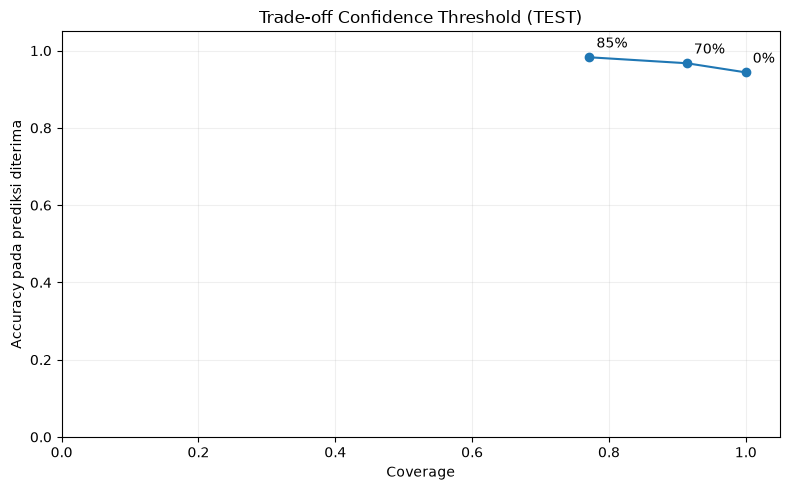

277

In [32]:
# Test semua skenario yang SUDAH dideklarasikan; tidak melakukan tuning dari test.
th_test=pd.DataFrame([coverage_metrics(y_test,selected_test_probs,t)
                      for t in CANDIDATE_THRESHOLDS])
th_test['selected_on_validation']=th_test.threshold.eq(chosen_threshold)
display(th_test.round(4))
th_test.to_csv(OUTPUT/'threshold_testing_skenario.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(th_test['coverage'],th_test['accepted_accuracy'],marker='o')
for r in th_test.itertuples():
    ax.annotate(f'{r.threshold:.0%}',(r.coverage,r.accepted_accuracy),xytext=(5,7),
                textcoords='offset points')
ax.set(title='Trade-off Confidence Threshold (TEST)',xlabel='Coverage',
       ylabel='Accuracy pada prediksi diterima',xlim=(0,1.05),ylim=(0,1.05))
ax.grid(alpha=.2);plt.tight_layout()
plt.savefig(OUTPUT/'fitur_unik_2_accuracy_coverage.png',dpi=160);plt.show()

(OUTPUT/'model_config.json').write_text(json.dumps({
    'selected_model':selected_name,'threshold':chosen_threshold,
    'class_names':class_names,'input_size':list(IMG_SIZE),
    'input_rule':'RGB, resize_with_pad 224x224, float pixels 0..255; normalisasi tertanam di model'
},indent=2,ensure_ascii=False))

---
# 10. Rekap konfigurasi, skenario, dan catatan pelaporan

**Skenario eksperimen yang sudah diselesaikan:** (A) CNN dari nol; (B) MobileNetV2 dengan pretrained ImageNet; (C) model terbaik + threshold 70%; (D) model terbaik + threshold 85%; (E) model terbaik + Grad-CAM. Untuk C/D/E **tidak perlu training ulang** karena merupakan post-processing/interpretabilitas.

In [33]:
experiment_recap=pd.DataFrame([
    {'skenario':'CNN baseline','model':'CNN Custom','fitur':'tanpa threshold',
     **summarize_metrics(y_test,test_probs_cnn)},
    {'skenario':'Transfer Learning baseline','model':'MobileNetV2','fitur':'tanpa threshold',
     **summarize_metrics(y_test,test_probs_mobile)},
])
display(experiment_recap.round(4))
experiment_recap.to_csv(OUTPUT/'rekap_skenario_baseline.csv',index=False)

# Simpan ringkasan jawaban untuk laporan. Analisis penyebab salah prediksi harus ditulis
# berdasarkan gambar/heatmap, bukan dibuat otomatis sebagai fakta.
selected_test=test_scores.loc[selected_name]
report_summary=(
    '# Ringkasan Hasil Deep Learning Coffee Cherry\n\n'
    f'- Sumber: {DATASET_URL}\n'
    f'- Format anotasi: {FORMAT}\n'
    f'- Foto asli unik beranotasi: {object_df.group_sha256.nunique()}\n'
    f'- Total objek hasil cleaning: {len(object_df)}\n'
    f'- Jumlah kelas: {num_classes}; {class_names}\n'
    f'- Crop train/validation/test: {len(train_df)}/{len(val_df)}/{len(test_df)}\n'
    f'- Model terpilih berdasar validation macro F1: {selected_name}\n'
    f'- TEST accuracy model terpilih: {selected_test.accuracy:.4f}\n'
    f'- TEST precision macro: {selected_test.precision_macro:.4f}\n'
    f'- TEST recall macro: {selected_test.recall_macro:.4f}\n'
    f'- TEST F1 macro: {selected_test.f1_macro:.4f}\n'
    f'- Threshold dipilih dari validation: {chosen_threshold:.0%}\n'
    f'- GPU runtime: {versions["GPU"]}\n\n'
    '## Interpretasi manual yang masih perlu dilengkapi\n'
    '- Jelaskan kesalahan klasifikasi yang paling sering terjadi (cek confusion matrix).\n'
    '- Bandingkan grafik loss/accuracy untuk overfitting/underfitting.\n'
    '- Jelaskan sampel Grad-CAM yang relevan dan tidak relevan.\n'
    '- Bahas accuracy–coverage trade-off dari threshold.\n'
    '- Keterbatasan: klasifikasi crop, bukan deteksi multiobjek otomatis.\n'
)
(OUTPUT/'RINGKASAN_HASIL_UNTUK_LAPORAN.md').write_text(report_summary,encoding='utf-8')
print(report_summary)

,skenario,model,fitur,accuracy,precision_macro,recall_macro,f1_macro
0,CNN baseline,CNN Custom,tanpa threshold,0.9437,0.9205,0.9376,0.9281
1,Transfer Learning baseline,MobileNetV2,tanpa threshold,0.9007,0.8661,0.8898,0.8766


# Ringkasan Hasil Deep Learning Coffee Cherry

- Sumber: https://www.kaggle.com/datasets/harisyunanda/dataset-coffee-cherry
- Format anotasi: YOLO
- Foto asli unik beranotasi: 432
- Total objek hasil cleaning: 2013
- Jumlah kelas: 3; ['Matang', 'Setengah Matang', 'Tidak Matang']
- Crop train/validation/test: 1404/307/302
- Model terpilih berdasar validation macro F1: CNN Custom
- TEST accuracy model terpilih: 0.9437
- TEST precision macro: 0.9205
- TEST recall macro: 0.9376
- TEST F1 macro: 0.9281
- Threshold dipilih dari validation: 85%
- GPU runtime: []

## Interpretasi manual yang masih perlu dilengkapi
- Jelaskan kesalahan klasifikasi yang paling sering terjadi (cek confusion matrix).
- Bandingkan grafik loss/accuracy untuk overfitting/underfitting.
- Jelaskan sampel Grad-CAM yang relevan dan tidak relevan.
- Bahas accuracy–coverage trade-off dari threshold.
- Keterbatasan: klasifikasi crop, bukan deteksi multiobjek otomatis.



---
# 11. Aplikasi Gradio dan hosting (ketentuan 7d)

Aplikasi menyediakan **upload satu crop buah kopi**, prediksi kelas, confidence semua kelas, keputusan diterima/ditolak berdasarkan threshold, dan overlay Grad-CAM.  
**Batasan produk:** untuk *gambar buah kopi individual*; mengunggah foto yang berisi banyak buah **tidak menghasilkan bounding box otomatis**. Aplikasi untuk demonstrasi akademis, bukan sistem sortasi lapangan yang telah teruji.

Notebook menyimpan `app.py`, `best_model.keras`, `class_names.json`, dan `model_config.json` agar dapat diunggah ke **Hugging Face Spaces** atau dijalankan lokal. Jika ingin menjalankan di Colab, gunakan sel Gradio di bawah; *public share* hanya jika memang menginginkannya.

In [34]:
# Simpan aset aplikasi dari model yang dipilih berdasar validation.
APP_DIR = ROOT/'aplikasi'
APP_DIR.mkdir(parents=True,exist_ok=True)
shutil.copy2(MODEL_DIR/'best_model.keras',APP_DIR/'best_model.keras')
shutil.copy2(OUTPUT/'class_names.json',APP_DIR/'class_names.json')
shutil.copy2(OUTPUT/'model_config.json',APP_DIR/'model_config.json')
print('Aset aplikasi:',sorted(p.name for p in APP_DIR.iterdir()))

Aset aplikasi: ['README.md', 'app.py', 'best_model.keras', 'class_names.json', 'model_config.json', 'requirements.txt']


In [35]:
# Menulis app.py mandiri untuk Hugging Face Spaces atau local run.
app_source = '"""Aplikasi demonstrasi hasil notebook Coffee Cherry (input: satu buah yang di-crop)."""\nimport json\nfrom pathlib import Path\nimport numpy as np\nimport cv2\nimport tensorflow as tf\nfrom PIL import Image\nimport gradio as gr\n\nBASE = Path(__file__).resolve().parent\nMODEL = tf.keras.models.load_model(BASE / \'best_model.keras\', compile=False)\nCLASS_NAMES = json.loads((BASE / \'class_names.json\').read_text(encoding=\'utf-8\'))\nCONFIG = json.loads((BASE / \'model_config.json\').read_text(encoding=\'utf-8\'))\nTHRESHOLD = float(CONFIG[\'threshold\'])\nIMG_SIZE = (224, 224)\n\n\ndef prepare(image):\n    im = image.convert(\'RGB\')\n    arr = np.asarray(im, dtype=np.uint8)\n    resized = tf.image.resize_with_pad(tf.convert_to_tensor(arr), *IMG_SIZE)\n    return tf.expand_dims(tf.cast(resized, tf.float32), 0)\n\n\ndef create_heatmap(batch, class_id):\n    feature_layer = MODEL.get_layer(\'feature_maps\')\n    grad_model = tf.keras.Model(MODEL.inputs, [feature_layer.output, MODEL.output])\n    with tf.GradientTape() as tape:\n        activation, scores = grad_model(batch, training=False)\n        loss = scores[:, class_id]\n    gradients = tape.gradient(loss, activation)\n    if gradients is None:\n        raise RuntimeError(\'Tidak dapat menghitung gradien visualisasi.\')\n    mean_grad = tf.reduce_mean(gradients, axis=(0, 1, 2))\n    saliency = tf.nn.relu(tf.reduce_sum(activation[0] * mean_grad, axis=-1))\n    saliency = saliency / (tf.reduce_max(saliency) + tf.keras.backend.epsilon())\n    original = np.uint8(np.clip(batch.numpy()[0], 0, 255))\n    colored = cv2.applyColorMap(np.uint8(cv2.resize(saliency.numpy(),\n                                        (original.shape[1], original.shape[0])) * 255), cv2.COLORMAP_JET)\n    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)\n    return Image.fromarray(np.uint8(0.6 * original + 0.4 * colored))\n\n\ndef predict(image):\n    if image is None:\n        return {}, \'Unggah gambar satu buah kopi terlebih dahulu.\', None\n    batch = prepare(image)\n    probabilities = MODEL.predict(batch, verbose=0)[0]\n    best = int(np.argmax(probabilities))\n    confidence = float(probabilities[best])\n    status = (\'DITERIMA\' if confidence >= THRESHOLD else \'DITOLAK (confidence rendah)\')\n    message = (f\'Model: {CONFIG["selected_model"]} | Prediksi: {CLASS_NAMES[best]} | \'\n               f\'Confidence: {confidence:.1%} | Threshold: {THRESHOLD:.0%} | {status}. \'\n               \'Catatan: hanya untuk gambar satu buah (crop), bukan foto multiobjek.\')\n    try:\n        overlay = create_heatmap(batch, best)\n    except Exception as exc:\n        overlay = None\n        message += f\' Grad-CAM tidak tersedia: {exc}\'\n    return {CLASS_NAMES[i]:float(p) for i,p in enumerate(probabilities)}, message, overlay\n\n\nwith gr.Blocks(title=\'Klasifikasi Kematangan Buah Kopi\') as demo:\n    gr.Markdown(\'# ☕ Klasifikasi Kematangan Buah Kopi\')\n    gr.Markdown(\'CNN/Transfer Learning — Unggah **crop satu buah kopi** (bukan foto banyak buah).\')\n    with gr.Row():\n        input_img = gr.Image(type=\'pil\', label=\'Gambar buah kopi\')\n        gradcam_img = gr.Image(label=\'Grad-CAM\', interactive=False)\n    btn = gr.Button(\'Prediksi Kematangan\', variant=\'primary\')\n    probabilities = gr.Label(num_top_classes=len(CLASS_NAMES), label=\'Probabilitas per kelas\')\n    message = gr.Textbox(label=\'Hasil dan keputusan threshold\', lines=3)\n    btn.click(fn=predict, inputs=input_img, outputs=[probabilities, message, gradcam_img])\n\n\nif __name__ == \'__main__\':\n    demo.launch()\n'
(APP_DIR/'app.py').write_text(app_source,encoding='utf-8')
requirements = (
    'tensorflow>=2.16,<2.22\n'
    'gradio>=4.44,<7\n'
    'numpy>=1.26,<3\n'
    'opencv-python-headless>=4.8\n'
    'Pillow>=10\n'
)
(APP_DIR/'requirements.txt').write_text(requirements,encoding='utf-8')
(APP_DIR/'README.md').write_text(
    '# Coffee Cherry Classification\n\n'
    'Gradio app. Input harus berupa potongan gambar satu buah kopi.\n'
    'Upload app.py, model_config.json, class_names.json, best_model.keras, '
    'dan requirements.txt ke Hugging Face Spaces (SDK Gradio).\n',encoding='utf-8')
print('Folder deploy:',APP_DIR)
print('Isi:',[p.name for p in APP_DIR.iterdir()])

Folder deploy: d:\DevOps\coffee_cherry\coffee_cherry_dl\aplikasi
Isi: ['app.py', 'best_model.keras', 'class_names.json', 'model_config.json', 'README.md', 'requirements.txt']


In [36]:
# Uji langsung aplikasi di notebook (opsional). Menggunakan app.py yang baru dibuat.
# Catatan: di Colab, share=False bisa tidak memberikan tautan publik;
# ubah ke share=True HANYA apabila ingin membagikan link sementara.
import importlib.util
spec=importlib.util.spec_from_file_location('coffee_app',APP_DIR/'app.py')
coffee_app=importlib.util.module_from_spec(spec)
spec.loader.exec_module(coffee_app)
print('Aplikasi Gradio siap.')
print('Model:',selected_name,'| threshold:',chosen_threshold)
# Jalankan manual bila siap membuka UI (hapus tanda # pada baris ini):
# coffee_app.demo.launch(share=True,debug=False)

Aplikasi Gradio siap.
Model: CNN Custom | threshold: 0.85


### Opsional: hosting Hugging Face Spaces

1. Buat **New Space** dengan **SDK: Gradio** di [Hugging Face Spaces](https://huggingface.co/spaces).
2. Upload seluruh isi folder aplikasi: `app.py`, `requirements.txt`, `best_model.keras`, `class_names.json`, `model_config.json`.
3. Tunggu dependensi terpasang, uji upload satu crop buah, catat URL dan screenshot.
4. Hosting **tidak otomatis** dari notebook karena memerlukan akun pengguna, konfigurasi, dan izin upload; hosting gratis mungkin memiliki batas CPU/RAM/waktu. Jika deployment tidak diminta, cukup demonstrasikan lewat Gradio Colab.

**Catatan reproduksibilitas:** `requirements.txt` menggunakan kisaran versi yang lazim kompatibel; jika lingkungan Spaces berbeda dari runtime training, sesuaikan versi setelah pengujian aktual. Untuk reproduksi persis, catat versi lingkungan pada `teknologi_versions.json`.

---
# 12. Bukti, file hasil, dan ekspor (ketentuan 7a–7d)

File laporan yang tersedia setelah menjalankan seluruh sel:

- Metadata dataset (`profil_dataset.json`, audit gambar, anotasi invalid, metadata crop).
- EDA (label, contoh per kelas, bbox asli, resolusi).
- Preprocessing (distribusi split anti-leakage, contoh augmentasi).
- Arsitektur & model (`model.summary()`, diagram jika `pydot/graphviz` tersedia, `.keras`).
- Training (kurva loss/accuracy dan CSV history).
- Evaluasi (classification report, confusion matrix, scorecard, salah prediksi).
- **Fitur unik** (visualisasi Grad-CAM, accuracy–coverage threshold).
- Teknologi (`teknologi_versions.json`), ringkasan laporan, paket aplikasi Gradio.

**Hal yang tetap harus ditulis oleh mahasiswa:** pembahasan hasil konkret, keputusan apakah model over/underfitting, penjelasan visualisasi Grad-CAM, sitasi referensi, serta kesimpulan yang tidak melampaui bukti. Notebook tidak dapat menjamin nilai metrik tertentu.

In [37]:
# Periksa dan simpulkan semua output. ZIP tidak memasukkan dataset mentah,
# sehingga lebih kecil dan menghormati sumber dataset asli Kaggle.
import subprocess
print('GPU (nvidia-smi jika tersedia):')
try:
    proc=subprocess.run(['nvidia-smi','--query-gpu=name,memory.total',
                         '--format=csv,noheader'],capture_output=True,text=True,timeout=8)
    print(proc.stdout.strip() or 'nvidia-smi tidak tersedia')
except (OSError,subprocess.TimeoutExpired):
    print('Tidak tersedia: gunakan informasi GPU TensorFlow di awal notebook.')

archive=ROOT/'COFFEE_CHERRY_HASIL_DAN_APLIKASI.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,
                     compresslevel=6) as z:
    for folder in [OUTPUT,APP_DIR]:
        for f in sorted(folder.rglob('*')):
            if f.is_file(): z.write(f,arcname=str(f.relative_to(ROOT)))
print('ARSIP HASIL:',archive)
print('Ukuran arsip (MB):',round(archive.stat().st_size/1024**2,2))
print('Jumlah file hasil:',sum(p.is_file() for p in OUTPUT.rglob('*')))

GPU (nvidia-smi jika tersedia):
Tidak tersedia: gunakan informasi GPU TensorFlow di awal notebook.
ARSIP HASIL: d:\DevOps\coffee_cherry\coffee_cherry_dl\COFFEE_CHERRY_HASIL_DAN_APLIKASI.zip
Ukuran arsip (MB): 25.15
Jumlah file hasil: 42


## 13. Template kesimpulan untuk diisi berdasarkan hasil (bukan angka contoh)

> Dataset yang digunakan adalah **Dataset Coffee Cherry** dari Kaggle. Setelah pembersihan, terdapat **[lihat `profil_dataset.json`]** objek pada **[lihat profil]** foto asli unik. Foto diubah menjadi crop satu buah dan dibagi dengan *group-aware split* agar foto yang sama tidak bocor antar split. Dua model yang dibandingkan adalah CNN custom dan Transfer Learning MobileNetV2. Pada data testing, CNN memperoleh macro F1 **[lihat `evaluasi_testing_perbandingan_model.csv`]**, sementara MobileNetV2 memperoleh **[lihat CSV]**. Model akhir dipilih berdasarkan **F1 macro validation**, bukan berdasarkan test. Grad-CAM digunakan sebagai analisis fokus model, sedangkan confidence threshold digunakan untuk menolak prediksi di bawah ambang tertentu dengan konsekuensi penurunan coverage. Keterbatasan utama sistem ini adalah **klasifikasi crop, bukan deteksi seluruh buah pada foto utuh**.

### Checklist akhir untuk tugas dosen

- [ ] Jumlah gambar dan anotasi **benar-benar dihitung**, bukan menyalin sumber lain.
- [ ] Nama kelas sesuai metadata Kaggle dan contoh gambar telah dicek.
- [ ] Semua kelas hadir pada train, validation, test; tidak ada overlap foto asli.
- [ ] Ada diagram/summary dan jumlah parameter kedua model.
- [ ] Ada **dua grafik** loss/accuracy **masing-masing** model.
- [ ] Ada accuracy, precision, recall, macro F1, confusion matrix kedua model.
- [ ] Ada analisis **dua fitur unik** (Grad-CAM dan threshold), bukan hanya kode.
- [ ] Ada tabel skenario dan ulasan kelas yang paling sering salah.
- [ ] Ada info versi Python/framework/GPU serta screenshot aplikasi.
- [ ] Keterbatasan, referensi, dan kesimpulan dijelaskan dengan data aktual.

### Referensi dasar

1. Kaggle — [Dataset Coffee Cherry oleh harisyunanda](https://www.kaggle.com/datasets/harisyunanda/dataset-coffee-cherry)
2. Howard et al. — [MobileNetV2: Inverted Residuals and Linear Bottlenecks](https://arxiv.org/abs/1801.04381)
3. Selvaraju et al. — [Grad-CAM: Visual Explanations from Deep Networks](https://arxiv.org/abs/1610.02391)
4. TensorFlow — [Keras MobileNetV2](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2)
5. TensorFlow — [Classification dataset loading and preprocessing](https://www.tensorflow.org/tutorials/load_data/images)

## Fitur unik 3 Eksperimen focal loss

In [ ]:
# Jalankan setelah baseline selesai. Tidak mengganti cnn, selected_model, atau aset aplikasi.
from pathlib import Path
import time
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def eksperimen_focal():
    folder = OUTPUT / 'tambahan_focal'
    folder.mkdir(exist_ok=True)
    results = []
    predictions = {}
    for name in ['kontrol_ce', 'focal_gamma2']:
        tf.keras.utils.set_random_seed(SEED)
        model = build_cnn()
        if name == 'focal_gamma2':
            def sparse_focal(y, prob):
                y = tf.cast(tf.reshape(y, [-1]), tf.int32)
                pt = tf.gather(prob, y, axis=1, batch_dims=1)
                pt = tf.clip_by_value(pt, 1e-7, 1.)
                return -tf.square(1.-pt) * tf.math.log(pt)
            model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=sparse_focal, metrics=['accuracy'])
        ckpt = folder / (name + '.weights.h5')
        callbacks = [tf.keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True, save_weights_only=True),
                     tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5),
                     tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=3, factor=.5, min_lr=1e-6)]
        start=time.perf_counter()
        hist=model.fit(make_dataset(train_df,training=True), validation_data=val_ds, epochs=EPOCHS_CNN,
                       class_weight=class_weight if USE_CLASS_WEIGHT else None, callbacks=callbacks, verbose=2)
        seconds=time.perf_counter()-start
        model.load_weights(ckpt)
        pd.DataFrame(hist.history,index=range(1,len(hist.epoch)+1)).to_csv(folder/(name+'_history.csv'),index_label='epoch')
        validation=summarize_metrics(val_df.class_id.to_numpy(),model.predict(val_ds,verbose=0))
        results.append(dict(model=name,seconds=seconds,epochs=len(hist.epoch),**validation))
        predictions[name]=model
    validation=pd.DataFrame(results)
    validation.to_csv(folder/'validation.csv',index=False)
    print('Terpilih pada validation:', validation.loc[validation.f1_macro.idxmax(),'model'])
    final=[]
    for name,model in predictions.items():
        probs=model.predict(test_ds,verbose=0)
        truth=test_df.class_id.to_numpy()
        final.append(dict(model=name,**summarize_metrics(truth,probs)))
        labels=list(range(len(class_names)))
        pd.DataFrame(confusion_matrix(truth,probs.argmax(1),labels=labels),index=class_names,columns=class_names).to_csv(folder/(name+'_matrix.csv'))
        pd.DataFrame(classification_report(truth,probs.argmax(1),labels=labels,target_names=class_names,output_dict=True,zero_division=0)).T.to_csv(folder/(name+'_per_class.csv'))
    return pd.DataFrame(final)
# Aktifkan untuk menjalankan eksperimen tambahan:
# display(eksperimen_focal())


## Fitur unik 4 Pemeriksaan kualitas mask

In [ ]:
# Audit independen dari prediksi baseline. Input adalah crop satu buah, bukan foto penuh.
from audit_mask import periksa_mask, audit_folder
# Contoh pada train (ubah indeks untuk memeriksa crop lain):
# overlay, status, proporsi = periksa_mask(train_df.iloc[0].crop_path)
# display(overlay); print(status, proporsi)
# audit_folder(train_df.crop_path, OUTPUT / 'tambahan_mask')
